# 02. FoldedVision AI — Lens 최종 딥러닝 통합

**주제:** CNN 기반 정밀 광학 렌즈의 외관 결함 검출 및 사전 품질검사 효과 분석 (공개 데이터 PoC)

이 노트북 하나로 다음을 모두 합니다. 01 Baseline 모델 파일이 없어도 처음부터 스스로 실행됩니다.
1. 데이터 준비·검사
2. 전처리 비교
3. Improved CNN
4. U-Net 결함 위치
5. 모델 비교·판정 경계
6. 사전 검사 효과 분석
7. Gradio 검사 화면
8. 팀 통합 파일 생성

### 정상 사진이 없는 문제를 이렇게 풀었습니다
| 문제 | 해결 |
|---|---|
| Lens 공식 정상 **사진** 0장 | 결함 사진 안의 **결함 없는 256×256 구역**을 정상(0), 결함 있는 구역을 불량(1)으로 하는 실제 마스크 기반 정답 |
| 사진 단위 판정 | 사진 점수 = 구역 점수 최댓값 → OK / REVIEW / NG |
| 정상 사진 오검출률 | 지금은 측정 불가. inference 93장에 정상 사진이 섞여 있으므로(공식 문서), **팀이 두 명 독립 라벨링한 CSV**를 넣으면 이 노트북이 자동으로 정상 사진 오검출률을 계산합니다(PART 08-2). |
| 같은 렌즈 누수 | 512 조각 가장자리 연결로 렌즈 묶음을 찾아 분할에 반영 |

> 공개 데이터 기술 검증(PoC)입니다. 자화전자 실제 생산 데이터·생산라인 성능이 아닙니다.

`[TF]` 셀은 TensorFlow가 필요합니다. **먼저 `RUN_MODE="quick"`으로 끝까지 실행해 오류가 없는지 확인하고, `"full"`로 실행하세요.**

In [1]:
# ── PART 01. 실행 설정 ──
from pathlib import Path
import os
NOTEBOOK_ID = "02"
DATASET_NAME = "Lens"
IMAGE_SIZE = 256
BATCH_SIZE = 16
SEED = 42
RUN_MODE = "full"
assert RUN_MODE in ("quick", "full")

TRAIN_IMPROVED_CNN = True
TRAIN_UNET = True
TRAIN_AUTOENCODER = False  # 정상 '사진'이 없어 기본은 실행하지 않음 (PART 05 설명)
USE_SAVED_MODELS = True
ENABLE_GRADIO = True  # 마지막에 로컬(127.0.0.1) 검사 화면을 엽니다.

LEARNING_RATE = 1e-3
CNN_EPOCHS = 2 if RUN_MODE == "quick" else 20  # 01과 같아야 Baseline 저장 모델을 재사용할 수 있습니다.
CNN_PATIENCE = 5
# Improved CNN 실험: 같은 분할에서 전처리 3가지 + 클래스 가중치 유무 비교
CNN_EXPERIMENTS = [
    {"id": "rgb_cw", "method": "rgb", "class_weight": True, "dropout": 0.3, "lr": 1e-3},
    {"id": "clahe_cw", "method": "clahe", "class_weight": True, "dropout": 0.3, "lr": 1e-3},
    {"id": "median_cw", "method": "median", "class_weight": True, "dropout": 0.3, "lr": 1e-3},
    {"id": "rgb_nocw", "method": "rgb", "class_weight": False, "dropout": 0.3, "lr": 1e-3},
]
if RUN_MODE == "quick":
    CNN_EXPERIMENTS = CNN_EXPERIMENTS[:2]

UNET_FILTERS = (16, 32, 64, 128)  # 인코더 1·2·3 + 병목
UNET_LOSSES = ["bce", "bce_dice"]
UNET_EPOCHS = 2 if RUN_MODE == "quick" else 25
UNET_PATIENCE = 6
UNET_THRESHOLDS = [round(0.10 + 0.05 * i, 2) for i in range(17)]
UNET_MIN_BLOB_PX = 4  # 예측 마스크에서 4픽셀 미만 점은 잡음으로 지움
UNET_EXPERIMENTAL_DICE = 0.5  # 검증 평균 Dice가 이보다 낮으면 '실험용 위치 표시'

SIM_PRODUCTION = 10000  # 사전 검사 시뮬레이션: 가상 생산 수량(가정)
SIM_DEFECT_RATES = [0.01, 0.03, 0.05]  # 가정한 불량 발생률(데이터셋 비율 아님)
MODEL_VERSION_TAG = "v1"

### 경로와 공통 규칙
- `full` 결과는 `models/`, `outputs/`에 지시서의 이름 그대로 저장합니다.
- `quick` 결과는 `models/quick/`, `outputs/quick/`에 따로 저장합니다. 최종 결과를 덮어쓰지 않기 위해서입니다.

| 이름 | 값 | 의미 |
|---|---|---|
| `IMAGE_SIZE` | 256 | 모델 입력 = 256×256 RGB **구역(patch)** |
| `LENS_TARGET_DEFECT_PX` | 20 | 줄인 사진에서 결함 한 변이 약 20픽셀이 되도록 사진 크기 묶음별 배율을 정합니다. 사진 전체를 256으로 줄이면 작은 결함이 사라지기 때문입니다. |
| `STRIDE` | 192 | 구역을 3/4씩 옮깁니다. 겹치게 해서 경계에 걸친 결함을 놓치지 않습니다. |
| `VALID_MIN` | 0.2 | 렌즈 면(밝은 영역)이 20% 미만인 구역(거의 검은 배경)은 검사하지 않습니다. |
| `MIN_DEFECT_PX` | 4 | 구역 안 결함 픽셀이 4개 이상이면 불량 구역, 0개면 정상 구역, 1~3개(가장자리에 살짝 걸침)는 애매해서 학습·평가에서 뺍니다. |

In [2]:
# ── 공통 경로·규칙 (두 노트북 동일) ──
ROOT = Path.cwd().resolve()  # FoldedVision_Lens 폴더에서 실행하세요.
QUICK = RUN_MODE == "quick"
MODEL_DIR = ROOT / ("models/quick" if QUICK else "models")
OUT_DIR = ROOT / ("outputs/quick" if QUICK else "outputs")
FIG_DIR, PRED_DIR, MET_DIR, INTEG_DIR = OUT_DIR / "figures", OUT_DIR / "predictions", OUT_DIR / "metrics", OUT_DIR / "integration"
PROCESSED = ROOT / "data/processed"
for folder in [ROOT / "data/archives", ROOT / "data/raw", PROCESSED, MODEL_DIR, FIG_DIR, PRED_DIR, MET_DIR, INTEG_DIR]:
    folder.mkdir(parents=True, exist_ok=True)  # 기존 파일은 지우지 않습니다.

LENS_TARGET_DEFECT_PX = 20
PATCH = IMAGE_SIZE  # 모델 입력 구역 한 변
STRIDE = PATCH * 3 // 4
VALID_MIN = 0.2
MIN_DEFECT_PX = 4
NEG_PER_POS = 2.0  # 학습 때 정상 구역을 불량 구역의 2배만 뽑습니다(전부 쓰면 정상이 너무 많음).
INTERNAL_VAL_FRACTION = 0.2  # 공식 train 안에서 내부 검증으로 떼는 비율(렌즈 묶음 단위)
RECALL_TARGET = 0.95  # NG 경계: 검증에서 불량 구역 Recall 95% 이상
REVIEW_RECALL = 0.99  # OK 경계: 검증에서 불량 구역 Recall 99% 이상(더 보수적) → 사이 구간이 REVIEW
QUICK_LIMIT = {"train": 8, "validation": 4, "test": 6}  # quick 모드에서 쓰는 사진 수
print("실행 모드:", RUN_MODE, "/ 모델 폴더:", MODEL_DIR, "/ 결과 폴더:", OUT_DIR)

실행 모드: full / 모델 폴더: C:\Project\Ai_Source\FoldedVision_Lens\models / 결과 폴더: C:\Project\Ai_Source\FoldedVision_Lens\outputs


In [3]:
# 공통 도구: 파일 지문·한글 경로 이미지 읽기·JSON 저장 (TensorFlow 불필요)
import sys, json, tarfile, shutil, hashlib, time, platform
from collections import Counter, defaultdict
from datetime import datetime, timezone, timedelta
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
os.environ.setdefault("GRADIO_ANALYTICS_ENABLED", "False")
import numpy as np
import pandas as pd
import cv2
import matplotlib
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix, roc_curve, precision_recall_curve)
KST = timezone(timedelta(hours=9))
plt.rcParams["font.family"] = "Malgun Gothic" if platform.system() == "Windows" else "DejaVu Sans"  # 한글 글꼴
plt.rcParams["axes.unicode_minus"] = False

def save_json(path, value):
    # 한글·들여쓰기 유지. NumPy 숫자도 일반 숫자로 바꿔 저장합니다.
    Path(path).write_text(json.dumps(value, ensure_ascii=False, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o)), encoding="utf-8")

def sha256_file(path):
    # 파일 내용 지문: 같은 파일인지, 모델이 바뀌었는지 확인합니다.
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

def read_rgb(path):
    # OpenCV는 BGR로 읽으므로 RGB로 바꿉니다. np.fromfile+imdecode는 한글 경로에서도 동작합니다.
    image = cv2.imdecode(np.fromfile(str(path), dtype=np.uint8), cv2.IMREAD_COLOR)
    if image is None:
        raise ValueError(f"이미지 읽기 실패(손상 가능): {path}")
    return cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

def save_png(path, rgb_or_gray):
    # 한글 경로에도 저장되도록 imencode + tofile을 씁니다.
    array = cv2.cvtColor(rgb_or_gray, cv2.COLOR_RGB2BGR) if rgb_or_gray.ndim == 3 else rgb_or_gray
    cv2.imencode(".png", array)[1].tofile(str(path))

In [4]:
# [TF] TensorFlow를 불러오고 실행 환경을 기록합니다.
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
tf.keras.utils.set_random_seed(SEED)  # Python·NumPy·TensorFlow 시드 고정
tf.config.threading.set_intra_op_parallelism_threads(4)
tf.config.threading.set_inter_op_parallelism_threads(2)
packages = {}
for name in ["gradio", "sklearn", "matplotlib"]:
    try:
        packages[name] = __import__(name).__version__
    except ImportError:
        packages[name] = "미설치"
environment = {"python": sys.version, "tensorflow": tf.__version__, "opencv": cv2.__version__, "numpy": np.__version__, "pandas": pd.__version__,
               "packages": packages, "gpu": [str(x) for x in tf.config.list_physical_devices("GPU")], "cpu": platform.processor(), "mode": RUN_MODE, "seed": SEED}
save_json(MET_DIR / f"environment_{NOTEBOOK_ID}.json", environment)
print(json.dumps(environment, ensure_ascii=False, indent=1))


{
 "python": "3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]",
 "tensorflow": "2.15.0",
 "opencv": "4.11.0",
 "numpy": "1.26.4",
 "pandas": "3.0.6",
 "packages": {
  "gradio": "6.32.0",
  "sklearn": "1.9.1",
  "matplotlib": "3.11.2"
 },
 "gpu": [],
 "cpu": "Intel64 Family 6 Model 197 Stepping 2, GenuineIntel",
 "mode": "full",
 "seed": 42
}


## 데이터 준비 — Lens.tar.gz 찾기와 안전한 압축 해제
1. **이미 풀린 폴더를 먼저 찾습니다.** `data` 아래에 Lens 폴더(`train/val/inference` + `_annotations.coco.json`)가 있으면 그대로 다시 씁니다. 압축을 다시 풀지 않습니다.
2. **없으면 압축파일을 찾습니다.** 찾는 순서는 현재 폴더 → `data/archives` → `data/raw` → `data` → Windows `다운로드` 폴더입니다. 이름은 `Lens.tar.gz`, `Lens_tar.gz` 둘 다 인식합니다. `data/archives` 밖에서 찾은 파일은 원본을 그대로 두고 **사본**을 `data/archives`에 둡니다.
3. **안전하게 풉니다.**
   - 압축 안 경로가 폴더 밖을 가리키거나(`..`, 절대경로) 링크·장치 파일이 있으면 멈춥니다.
   - 맥 메타데이터(`._*`)는 풀지 않습니다.
   - 임시 폴더에 다 푼 뒤에만 `data/raw/Lens_extracted`로 이름을 바꿉니다.
4. **어디에도 없으면** Hugging Face 공식 저장소에서 `Lens.tar.gz` 하나만 받습니다. 이 데이터셋은 이용 조건 동의가 필요한 '게이트' 데이터입니다. `huggingface-cli login`으로 로그인하고 웹에서 조건에 동의한 경우에만 받아집니다.

In [5]:
# Lens 데이터 폴더 찾기 → 없으면 압축 해제 → 그래도 없으면 공식 저장소에서 받기
HF_REPO, HF_FILE = "VISION-Workshop/VISION-Datasets", "Lens.tar.gz"

def find_lens_dataset_dirs(base):
    found = set()
    for annotation in Path(base).rglob("_annotations.coco.json"):
        top = annotation.parent.parent
        if annotation.parent.name == "train" and (top / "val/_annotations.coco.json").exists() and not top.name.startswith("."):
            found.add(top.resolve())
    return sorted(found)

def find_archives():
    places = [ROOT, ROOT / "data/archives", ROOT / "data/raw", ROOT / "data", Path.home() / "Downloads"]
    by_hash = {}
    for place in places:
        if not place.is_dir():
            continue
        for path in place.glob("Lens*"):
            if path.is_file() and (path.name.endswith(".gz") or path.name.endswith(".tgz")):
                by_hash.setdefault(sha256_file(path), path.resolve())  # 같은 내용이면 한 번만
    return by_hash

def safe_extract_tar(archive, destination):
    destination = Path(destination).resolve()
    with tarfile.open(archive, "r:*") as pack:
        members = pack.getmembers()
        if len(members) > 20000 or sum(m.size for m in members) > 5 * 1024**3:
            raise ValueError("예상하지 못한 압축 항목 수 또는 크기")
        for member in members:  # 쓰기 전에 전부 검사
            name = member.name.replace(chr(92), "/")
            if Path(name).is_absolute() or ".." in Path(name).parts or ":" in name:
                raise ValueError(f"압축파일 경로 이탈: {member.name}")
            if member.issym() or member.islnk() or member.isdev():
                raise ValueError(f"링크·장치 파일은 허용하지 않습니다: {member.name}")
        written = 0
        for member in members:
            if not member.isfile() or Path(member.name).name.startswith("._"):
                continue
            target = (destination / member.name).resolve()
            if not target.is_relative_to(destination):
                raise ValueError("압축파일 경로 이탈")
            target.parent.mkdir(parents=True, exist_ok=True)
            with pack.extractfile(member) as source, target.open("wb") as stream:
                shutil.copyfileobj(source, stream, length=1024 * 1024)
            written += 1
    return written

def download_from_hf():
    try:
        from huggingface_hub import hf_hub_download
    except ImportError:
        raise FileNotFoundError("Lens.tar.gz가 없습니다. 공식 VISION-Datasets에서 Lens.tar.gz를 받아 data/archives에 넣거나, pip install huggingface_hub 후 로그인하세요.")
    try:
        return Path(hf_hub_download(HF_REPO, HF_FILE, repo_type="dataset", local_dir=ROOT / "data/archives"))
    except Exception as error:
        raise FileNotFoundError(f"공식 저장소 다운로드 실패({type(error).__name__}). 이용 조건 동의·로그인이 필요한 데이터셋입니다: {error}")

def prepare_lens():
    existing = find_lens_dataset_dirs(ROOT / "data")
    archives = find_archives()
    if len(archives) > 1:
        raise ValueError("내용이 다른 Lens 압축파일이 여러 개입니다: " + ", ".join(map(str, archives.values())))
    archive_info = None
    if archives:
        archive_hash, archive = next(iter(archives.items()))
        if archive.parent != (ROOT / "data/archives").resolve():
            kept = ROOT / "data/archives" / ("Lens.tar.gz" if archive.name.endswith(".gz") else archive.name)
            if not kept.exists():
                shutil.copy2(archive, kept)  # 원본은 두고 사본을 프로젝트에 보관
            archive = kept
        archive_info = {"path": str(archive.relative_to(ROOT)), "bytes": archive.stat().st_size, "sha256": archive_hash}
    if len(existing) == 1:
        return existing[0], {"how": "이미 풀린 폴더 재사용", "archive": archive_info}
    if len(existing) > 1:
        raise ValueError("Lens 폴더가 여러 곳에 있습니다:\n" + "\n".join(map(str, existing)))
    if archive_info is None:
        archive = download_from_hf()
        archive_info = {"path": str(archive.relative_to(ROOT)), "bytes": archive.stat().st_size, "sha256": sha256_file(archive), "source": "huggingface"}
    extract_root = (ROOT / "data/raw/Lens_extracted").resolve()
    if extract_root.exists():
        raise ValueError(f"{extract_root} 가 있지만 Lens 구조가 아닙니다. 확인 후 이름을 바꿔 주세요(자동 삭제 안 함).")
    temporary = extract_root.with_name(".Lens_extracting")
    if temporary.exists():
        shutil.rmtree(temporary)  # 이전에 중단된 '임시' 해제본만 지웁니다.
    written = safe_extract_tar(ROOT / archive_info["path"], temporary)
    temporary.rename(extract_root)
    save_json(extract_root / ".complete.json", {**archive_info, "files_written": written, "extracted_at": datetime.now(KST).isoformat()})
    found = find_lens_dataset_dirs(extract_root)
    if len(found) != 1:
        raise ValueError("압축 안에서 Lens train/val 구조를 찾지 못했습니다.")
    return found[0], {"how": "지금 압축 해제", "files_written": written, "archive": archive_info}

LENS_DATA_DIR, LENS_SOURCE = prepare_lens()
save_json(MET_DIR / "lens_acquisition.json", {"dataset_dir": str(LENS_DATA_DIR), "official_source": HF_REPO + " / " + HF_FILE, **LENS_SOURCE})
print("Lens 데이터 폴더:", LENS_DATA_DIR, "/", LENS_SOURCE["how"])

Lens 데이터 폴더: C:\Project\Ai_Source\FoldedVision_Lens\data\Lens\Lens / 이미 풀린 폴더 재사용


## 데이터 구조 검사와 정상/불량 라벨 검증
COCO JSON의 `images`, `annotations`, `categories`를 직접 읽고 실제 사진 파일과 하나씩 대조합니다.
- 연결: JSON의 사진이 실제로 있는지, 반대로 JSON에 없는 사진은 없는지
- 손상·크기: 사진이 열리는지, JSON 크기와 실제 크기가 같은지
- bbox·polygon: 둘 다 있는지, polygon이 3점 이상이고 사진 범위 안인지, bbox와 범위가 맞는지
- 중복: 픽셀이 완전히 같은 사진이 있는지
- **정상/불량:** 정답이 있는 사진 중 결함 주석이 0개인 사진이 있는지(= 공식 정상 사진). 주석 없는 inference 사진을 정상으로 간주하지 않습니다.

In [6]:
# COCO 주석과 실제 사진을 하나씩 대조합니다.
LENS_SPLITS = ("train", "val", "inference")

def capture_group(width, height):
    # 사진 크기로 촬영 조건을 묶습니다. 학습에 없던 크기는 'other' = 적용 범위 밖입니다.
    if (width, height) == (512, 512):
        return "A_512_quadrant"
    if (width, height) == (2448, 2048):
        return "B_2448x2048"
    if min(width, height) >= 3000 and abs(width - height) <= 0.05 * max(width, height):
        return "C_3500_square"
    return "other"

def audit_lens():
    images, instances, errors, macos_meta, categories, coco_keys = [], [], [], [], {}, {}
    for split in LENS_SPLITS:
        folder = LENS_DATA_DIR / split
        coco = json.loads((folder / "_annotations.coco.json").read_text(encoding="utf-8"))
        coco_keys[split] = sorted(coco.keys())
        categories[split] = [(int(c["id"]), c["name"]) for c in coco["categories"]]
        disk = {p.name for p in folder.glob("*.jpg") if not p.name.startswith("._")}
        macos_meta += [f"{split}/{p.name}" for p in folder.glob("._*")]
        listed = [i["file_name"] for i in coco["images"]]
        errors += [{"split": split, "file": n, "reason": "JSON에 없는 사진"} for n in sorted(disk - set(listed))]
        errors += [{"split": split, "file": n, "reason": "사진 파일 없음"} for n in sorted(set(listed) - disk)]
        if len(listed) != len(set(listed)):
            errors.append({"split": split, "reason": "JSON 사진 이름 중복"})
        by_image = defaultdict(list)
        for annotation in coco["annotations"]:
            by_image[annotation["image_id"]].append(annotation)
        names = dict(categories[split])
        for info in coco["images"]:
            path = folder / info["file_name"]
            if not path.exists():
                continue
            try:
                rgb = read_rgb(path)
            except ValueError as error:
                errors.append({"split": split, "file": info["file_name"], "reason": str(error)})
                continue
            height, width = rgb.shape[:2]
            if (width, height) != (info["width"], info["height"]):
                errors.append({"split": split, "file": info["file_name"], "reason": "JSON 크기와 실제 크기 불일치"})
            key = f"{split}/{info['file_name']}"
            annotations = by_image.get(info["id"], [])
            images.append({"image_key": key, "image_id": key.replace("/", "_").replace(".jpg", ""), "official_split": split, "file": info["file_name"],
                           "path": str(path.relative_to(ROOT)) if path.is_relative_to(ROOT) else str(path), "width": width, "height": height,
                           "capture_group": capture_group(width, height), "labeled": split != "inference", "n_instances": len(annotations),
                           "pixel_hash": hashlib.sha256(str(rgb.shape).encode() + rgb.tobytes()).hexdigest(),
                           "gray_like": bool(max(np.abs(rgb[..., 0].astype(int) - rgb[..., 1]).max(), np.abs(rgb[..., 1].astype(int) - rgb[..., 2]).max()) <= 8)})
            for annotation in annotations:
                problems = []
                polygons = annotation.get("segmentation") or []
                if isinstance(polygons, dict):
                    problems.append("RLE 형식(미지원)")
                    polygons = []
                points = [np.array(p, dtype=float).reshape(-1, 2) for p in polygons if len(p) >= 6]
                if not points:
                    problems.append("polygon 없음 또는 3점 미만")
                if any((p[:, 0] < -1).any() or (p[:, 0] > width + 1).any() or (p[:, 1] < -1).any() or (p[:, 1] > height + 1).any() for p in points):
                    problems.append("polygon이 사진 범위 밖")
                bbox = annotation.get("bbox")
                if not bbox:
                    problems.append("bbox 없음")
                    bbox = [0, 0, 0, 0]
                x, y, w, h = bbox
                if points:
                    allp = np.vstack(points)
                    if max(abs(allp[:, 0].min() - x), abs(allp[:, 1].min() - y), abs(allp[:, 0].max() - (x + w)), abs(allp[:, 1].max() - (y + h))) > 2:
                        problems.append("bbox와 polygon 범위 불일치")
                polygon_area = float(sum(abs(cv2.contourArea(p.astype(np.float32))) for p in points))
                instances.append({"image_key": key, "official_split": split, "annotation_id": annotation["id"], "category_id": int(annotation["category_id"]),
                                  "category": names.get(annotation["category_id"], "?"), "bbox_x": x, "bbox_y": y, "bbox_w": w, "bbox_h": h, "max_side": max(w, h),
                                  "center_x_norm": (x + w / 2) / width, "center_y_norm": (y + h / 2) / height, "coco_area": annotation.get("area"),
                                  "polygon_area": polygon_area, "polygon_fill_of_bbox": polygon_area / max(1.0, w * h), "n_polygons": len(points),
                                  "problems": ";".join(problems), "segmentation": json.dumps(polygons)})
                if problems:
                    errors.append({"split": split, "file": info["file_name"], "annotation_id": annotation["id"], "reason": ";".join(problems)})
    images, instances = pd.DataFrame(images), pd.DataFrame(instances)
    if len({tuple(v) for v in categories.values()}) != 1:
        errors.append({"reason": "폴더마다 결함 종류 목록이 다름"})
    labeled = images[images.labeled]
    duplicates = images[images.duplicated("pixel_hash", keep=False)]
    report = {
        "coco_top_level_keys": coco_keys, "categories": categories["train"],
        "total_images": int(len(images)), "images_per_split": images.groupby("official_split").size().to_dict(),
        "normal_images_official": int((labeled.n_instances == 0).sum()), "defect_images_official": int((labeled.n_instances > 0).sum()),
        "inference_images_without_label": int((images.official_split == "inference").sum()),
        "instances_per_split": instances.groupby("official_split").size().to_dict(),
        "instances_per_category": instances.category.value_counts().to_dict(),
        "images_containing_category": instances.groupby("category").image_key.nunique().to_dict(),
        "resolution_counts": (images.width.astype(str) + "x" + images.height.astype(str)).value_counts().to_dict(),
        "capture_groups": pd.crosstab(images.official_split, images.capture_group).to_dict(),
        "bbox_present": bool((instances.bbox_w > 0).all()), "polygon_present": bool((instances.n_polygons > 0).all()),
        "exact_duplicate_rows": int(len(duplicates)), "exact_duplicate_groups": [list(g.image_key) for _, g in duplicates.groupby("pixel_hash")],
        "gray_like_images": int(images.gray_like.sum()), "macos_metadata_files_skipped": len(macos_meta), "errors": errors,
        "binary_label_supported_at_image_level": bool((labeled.n_instances == 0).sum() > 0),
    }
    return images, instances, report

lens_images, lens_instances, lens_audit = audit_lens()
LENS_CATEGORIES = [name for _, name in sorted(lens_audit["categories"])]
print("전체 사진:", lens_audit["total_images"], "/ 공식 폴더별:", lens_audit["images_per_split"])
print("정답 있는 사진 중 정상:", lens_audit["normal_images_official"], "장 / 불량:", lens_audit["defect_images_official"], "장 / 정답 없는 inference:", lens_audit["inference_images_without_label"], "장")
print("결함 종류:", LENS_CATEGORIES)
print("결함 개수:", lens_audit["instances_per_category"])
print("bbox 있음:", lens_audit["bbox_present"], "/ polygon 있음:", lens_audit["polygon_present"], "/ 정확한 중복:", lens_audit["exact_duplicate_rows"], "/ 오류:", len(lens_audit["errors"]))
if lens_audit["errors"]:
    raise ValueError("연결·손상·형식 오류가 있습니다. 출력된 오류를 확인하세요.")
if not lens_audit["binary_label_supported_at_image_level"]:
    print("→ 공식 정상 사진이 없어 '사진 단위' 정상/불량 정답은 없습니다. 아래에서 '구역 단위' 정상/불량 정답을 실제 마스크로 만듭니다.")

전체 사진: 222 / 공식 폴더별: {'inference': 93, 'train': 66, 'val': 63}
정답 있는 사진 중 정상: 0 장 / 불량: 129 장 / 정답 없는 inference: 93 장
결함 종류: ['Fiber', 'Flash Particle', 'Hole', 'Surface Damage', 'Tear']
결함 개수: {'Fiber': 515, 'Surface Damage': 105, 'Tear': 35, 'Hole': 28, 'Flash Particle': 16}
bbox 있음: True / polygon 있음: True / 정확한 중복: 0 / 오류: 0
→ 공식 정상 사진이 없어 '사진 단위' 정상/불량 정답은 없습니다. 아래에서 '구역 단위' 정상/불량 정답을 실제 마스크로 만듭니다.


### 같은 렌즈의 조각 찾기 (누수 점검)
512×512 사진은 둥근 렌즈를 4등분한 조각입니다(한쪽 모서리가 검은 배경). 같은 렌즈의 이웃 조각이라면 **맞닿는 가장자리 픽셀**이 거의 같습니다. 가장자리 밝기 차이(평균 절댓값)를 비교해 다음 세 조건을 모두 만족하면 같은 렌즈로 묶습니다.
- 서로가 1등 짝일 것
- 차이가 1.6 이하일 것
- 2등 후보보다 1.3배 이상 확실할 것

이 묶음(`lens_group`)은 분할할 때 **같은 렌즈가 학습과 평가에 동시에 들어가지 않게** 하는 데 씁니다. 이 묶음은 추정이며, 큰 사진끼리 같은 렌즈를 다시 찍었는지는 확인할 수 없습니다.

In [7]:
# 512×512 사분면 조각의 가장자리를 비교해 같은 렌즈 묶음(lens_group)을 만듭니다.
def dark_corner(gray):
    corners = {"TL": gray[:20, :20].mean(), "TR": gray[:20, -20:].mean(), "BL": gray[-20:, :20].mean(), "BR": gray[-20:, -20:].mean()}
    return min(corners, key=corners.get)  # 가장 어두운 모서리 = 렌즈 바깥 → 어느 사분면인지

def find_quadrant_links(frame, max_diff=1.6, min_ratio=1.3):
    rows = frame[frame.capture_group == "A_512_quadrant"]
    gray = {r.image_key: cv2.cvtColor(read_rgb(ROOT / r.path), cv2.COLOR_RGB2GRAY).astype(np.float32) for r in rows.itertuples()}
    quadrant = {k: dark_corner(g) for k, g in gray.items()}
    links = []
    for first, second, edge in [("TL", "TR", "h"), ("BL", "BR", "h"), ("TL", "BL", "v"), ("TR", "BR", "v")]:
        left, right = [k for k in gray if quadrant[k] == first], [k for k in gray if quadrant[k] == second]
        if not left or not right:
            continue
        diff = np.array([[np.abs(gray[a][:, -1] - gray[b][:, 0]).mean() if edge == "h" else np.abs(gray[a][-1, :] - gray[b][0, :]).mean() for b in right] for a in left])
        for i, a in enumerate(left):
            j = int(diff[i].argmin())
            best, runner = float(diff[i, j]), (float(np.sort(diff[i])[1]) if diff.shape[1] > 1 else np.inf)
            mutual = int(diff[:, j].argmin()) == i
            links.append({"first": a, "second": right[j], "pair": first + "-" + second, "edge_diff": round(best, 3), "second_best": round(runner, 3),
                          "accepted": bool(mutual and best <= max_diff and runner >= min_ratio * best)})
    return pd.DataFrame(links), quadrant

def union_groups(keys, pairs):
    parent = {k: k for k in keys}
    def root(k):
        while parent[k] != k:
            parent[k] = parent[parent[k]]
            k = parent[k]
        return k
    for a, b in pairs:
        parent[root(a)] = root(b)
    roots = {k: root(k) for k in keys}
    names = {r: f"L{i:03d}" for i, r in enumerate(sorted(set(roots.values())))}
    return {k: names[r] for k, r in roots.items()}

quad_links, quad_position = find_quadrant_links(lens_images)
pairs = [(r.first, r.second) for r in quad_links[quad_links.accepted].itertuples()] + [(g[0], o) for g in lens_audit["exact_duplicate_groups"] for o in g[1:]]
lens_images["quadrant"] = lens_images.image_key.map(quad_position).fillna("")
lens_images["lens_group"] = lens_images.image_key.map(union_groups(list(lens_images.image_key), pairs))
quad_links.to_csv(PROCESSED / "lens_quadrant_links.csv", index=False, encoding="utf-8-sig")
spans = lens_images.groupby("lens_group").official_split.agg(lambda s: set(s))
lens_audit.update({"quadrant_links_accepted": int(quad_links.accepted.sum()),
                   "groups_spanning_official_train_and_val": int(spans.map(lambda s: {"train", "val"} <= s).sum()),
                   "groups_spanning_labeled_and_inference": int(spans.map(lambda s: "inference" in s and bool(s & {"train", "val"})).sum())})
save_json(PROCESSED / "lens_audit.json", lens_audit)
lens_images.to_csv(PROCESSED / "lens_image_manifest.csv", index=False, encoding="utf-8-sig")
lens_instances.drop(columns=["segmentation"]).to_csv(PROCESSED / "lens_instances.csv", index=False, encoding="utf-8-sig")
print("같은 렌즈 연결:", lens_audit["quadrant_links_accepted"], "쌍 / 공식 train·val에 걸친 렌즈:", lens_audit["groups_spanning_official_train_and_val"],
      "/ 정답 사진·inference에 걸친 렌즈:", lens_audit["groups_spanning_labeled_and_inference"])

같은 렌즈 연결: 43 쌍 / 공식 train·val에 걸친 렌즈: 8 / 정답 사진·inference에 걸친 렌즈: 12


## 학습·검증·최종 평가 분할
지시서 원칙대로 **공식 Train 안에서 내부 검증을 만들고, 공식 Val을 최종 평가(test)로 유지합니다.** 같은 렌즈 누수를 막기 위해 두 가지를 더 합니다.

1. **공식 Val → test:** 단, 공식 Train과 같은 렌즈로 판단된 Val 사진은 test에서 **뺍니다**(`excluded_same_lens_as_train`, 11장). 이 사진은 학습에도 넣지 않습니다.
2. **공식 Train → train / validation:** 렌즈 묶음 단위로 섞어서(시드 42) 촬영 크기 묶음마다 약 80% / 20%로 나눕니다.

- 모델·전처리·경계 선택에는 **validation만** 씁니다.
- test는 모든 선택이 끝난 뒤에 평가합니다.
- inference(정답 없음)는 정량 평가에 쓰지 않습니다.

In [8]:
# 공식 Val은 최종 평가로 유지하고, 공식 Train만 렌즈 묶음 단위로 train/validation으로 나눕니다.
rng = np.random.default_rng(SEED)
lens_images["split"] = "inference"
train_groups = set(lens_images.loc[lens_images.official_split == "train", "lens_group"])
is_val = lens_images.official_split == "val"
leaked = is_val & lens_images.lens_group.isin(train_groups)
lens_images.loc[is_val & ~leaked, "split"] = "test"
lens_images.loc[leaked, "split"] = "excluded_same_lens_as_train"
official_train = lens_images[lens_images.official_split == "train"]
for _, block in official_train.groupby("capture_group"):
    groups = sorted(block.lens_group.unique())
    rng.shuffle(groups)
    sizes, running = block.groupby("lens_group").size(), 0
    for group in groups:
        chosen = "validation" if running / len(block) < INTERNAL_VAL_FRACTION else "train"
        lens_images.loc[(lens_images.lens_group == group) & (lens_images.official_split == "train"), "split"] = chosen
        running += sizes[group]

used = lens_images[lens_images.split.isin(["train", "validation", "test"])]
for column in ["lens_group", "pixel_hash"]:
    assert (used.groupby(column).split.nunique() == 1).all(), f"{column} 기준 분할 누수"
image_split = lens_images.set_index("image_key").split
lens_instances["split"] = lens_instances.image_key.map(image_split)
lens_instances["capture_group"] = lens_instances.image_key.map(lens_images.set_index("image_key").capture_group)
SPLIT_SIGNATURE = hashlib.sha256(json.dumps(sorted(zip(lens_images.image_key, lens_images.split, lens_images.pixel_hash))).encode()).hexdigest()
lens_images.to_csv(PROCESSED / "lens_split_manifest.csv", index=False, encoding="utf-8-sig")
split_table = pd.crosstab(lens_images.split, lens_images.capture_group, margins=True)
print(split_table)
print(pd.crosstab(lens_instances.category, lens_instances.split))

def split_keys(split):
    keys = sorted(lens_images.loc[lens_images.split == split, "image_key"])
    return keys[: QUICK_LIMIT[split]] if QUICK and split in QUICK_LIMIT else keys

capture_group                A_512_quadrant  B_2448x2048  C_3500_square  All
split                                                                       
excluded_same_lens_as_train              11            0              0   11
inference                                21           42             30   93
test                                     12           22             18   52
train                                    16           20             14   50
validation                                7            5              4   16
All                                      67           89             66  222
split           excluded_same_lens_as_train  test  train  validation
category                                                            
Fiber                                    20   243    205          47
Flash Particle                            0     8      3           5
Hole                                      1    13     11           3
Surface Damage                         

## 작업 배율·정답 마스크·렌즈 영역
- **작업 배율:** *train 결함 크기만 보고* 사진 크기 묶음별로 정합니다. 계산식은 `20 ÷ (train 결함 bbox 긴 변의 중앙값)`이고, 0.25~1.0으로 제한합니다. 사진은 `INTER_AREA`로 줄입니다.
- **정답 마스크:** polygon 좌표에 배율을 곱한 뒤 그 크기에서 직접 그립니다(`cv2.fillPoly`). 큰 마스크를 줄이다가 작은 결함이 사라지는 일이 없습니다. 마스크를 resize해야 할 때는 최근접 보간만 씁니다.
- **렌즈 영역:** 밝은 렌즈 면(밝기 > 60)만 '검사 영역'으로 봅니다. 사진 픽셀만으로 계산하고 정답은 쓰지 않습니다. 검은 배경·고정틀·가림 사각형은 검사하지 않습니다.

In [9]:
# train 결함 크기로 배율을 정하고, 줄인 사진·마스크·렌즈 영역을 준비합니다.
train_sizes = lens_instances[lens_instances.split == "train"].groupby("capture_group").max_side.median()
LENS_SCALE = {g: float(np.clip(LENS_TARGET_DEFECT_PX / s, 0.25, 1.0)) for g, s in train_sizes.items() if g != "other"}
print("train 결함 긴 변 중앙값:", train_sizes.round(1).to_dict(), "→ 작업 배율:", {k: round(v, 3) for k, v in LENS_SCALE.items()})

def to_work(rgb, group):
    scale = LENS_SCALE[group]
    height, width = rgb.shape[:2]
    if scale == 1.0:
        return rgb.copy(), scale
    return cv2.resize(rgb, (max(1, round(width * scale)), max(1, round(height * scale))), interpolation=cv2.INTER_AREA), scale

def valid_region(rgb):
    # 밝은 렌즈 면만 True (사진 픽셀만 사용)
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    mask = (cv2.GaussianBlur(gray, (5, 5), 0) > 60).astype(np.uint8)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, np.ones((5, 5), np.uint8))
    count, labels, stats, _ = cv2.connectedComponentsWithStats(mask)
    keep = np.zeros(count, bool)
    keep[1:] = stats[1:, cv2.CC_STAT_AREA] >= 0.05 * mask.size
    return keep[labels]

def rasterize(rows, shape, scale):
    mask = np.zeros(shape, np.uint8)
    instances = []
    for row in rows.itertuples():
        points = [np.round(np.array(p, np.float32).reshape(-1, 2) * scale).astype(np.int32) for p in json.loads(row.segmentation) if len(p) >= 6]
        if not points:
            continue
        cv2.fillPoly(mask, points, 1)
        allp = np.vstack(points)
        x0, y0 = max(0, int(allp[:, 0].min())), max(0, int(allp[:, 1].min()))
        local = np.zeros((int(allp[:, 1].max()) - y0 + 1, int(allp[:, 0].max()) - x0 + 1), np.uint8)
        cv2.fillPoly(local, [p - np.array([x0, y0], np.int32) for p in points], 1)
        local = local[: shape[0] - y0, : shape[1] - x0].astype(bool)
        instances.append({"category": row.category_id, "y0": y0, "x0": x0, "y1": y0 + local.shape[0], "x1": x0 + local.shape[1], "mask": local, "points": points})
    return mask, instances

lens_work = {}
vanished = 0
for split in ("train", "validation", "test"):
    for key in split_keys(split):
        row = lens_images.set_index("image_key").loc[key]
        image, scale = to_work(read_rgb(ROOT / row.path), row.capture_group)
        mask, instances = rasterize(lens_instances[lens_instances.image_key == key], image.shape[:2], scale)
        vanished += sum(int(not inst["mask"].any()) for inst in instances)
        lens_work[key] = {"image": image, "mask": mask, "instances": instances, "valid": valid_region(image), "split": split, "group": row.capture_group, "scale": scale}
print("준비한 사진:", len(lens_work), "/ 줄인 뒤 사라진 결함:", vanished)

train 결함 긴 변 중앙값: {'A_512_quadrant': 21.0, 'B_2448x2048': 25.0, 'C_3500_square': 38.0} → 작업 배율: {'A_512_quadrant': 0.952, 'B_2448x2048': 0.8, 'C_3500_square': 0.526}
준비한 사진: 118 / 줄인 뒤 사라진 결함: 0


## 구역(patch) 단위 정상/불량 정답 — 정상 사진이 없을 때의 해결 방법
Lens에는 공식 정상 **사진**이 없습니다. 하지만 결함 사진 안에서 **정답 polygon이 하나도 없는 구역**은 라벨러가 "결함 없음"으로 판단한 실제 정상 영역입니다. 그래서 이렇게 정답을 만듭니다.

| 구역 정답 | 조건 |
|---|---|
| **불량 = 1** | 256×256 구역 안 결함 픽셀이 4개 이상 |
| **정상 = 0** | 구역 안 결함 픽셀이 0개 |
| 제외 | 1~3개(결함 가장자리가 살짝 걸친 애매한 구역) |

- 구역 위치는 **사진 크기만으로** 정해지는 격자입니다(정답을 보고 고르지 않음).
- 불량 사진의 모든 구역을 불량으로 붙이지 않습니다.
- 렌즈 면이 20% 미만인 구역은 검사하지 않습니다.
- **train:** 불량 구역 전부 + 결함 중심을 조금 옮긴 구역(결함당 1개, 학습 샘플링 전용) + 정상 구역(불량의 2배를 무작위 추출)
- **validation·test:** 격자 구역 **전부**를 실제 비율 그대로 씁니다(정상이 훨씬 많음).

**사진 판정으로 합치는 방법:** 사진 점수 = 그 사진의 모든 구역 점수 중 **최댓값**입니다. 한 구역이라도 불량 점수가 높으면 그 사진은 불량 쪽입니다.

**한계:** 이것은 "결함 사진 안의 정상 영역"입니다. 결함이 전혀 없는 렌즈 사진에서의 오검출률은 진짜 정상 사진이 있어야 정확히 잴 수 있습니다. 02 노트북의 '팀 라벨 정상 사진' 셀이 그 부분을 채우는 방법입니다.

In [10]:
# 사진 크기만으로 정해지는 격자 구역과 구역 정답(정상 0 / 불량 1 / 제외 -1)을 만듭니다.
def grid_starts(length, patch=PATCH, stride=STRIDE):
    if length <= patch:
        return [0]
    starts = list(range(0, length - patch + 1, stride))
    if starts[-1] != length - patch:
        starts.append(length - patch)
    return starts

def pad_to(array, patch=PATCH):
    pad_h, pad_w = max(0, patch - array.shape[0]), max(0, patch - array.shape[1])
    if pad_h or pad_w:
        array = np.pad(array, ((0, pad_h), (0, pad_w)) + ((0, 0),) * (array.ndim - 2))
    return array

def grid_positions(image_shape, valid):
    # 렌즈 면이 VALID_MIN 이상인 격자 구역만 검사합니다. (사진 픽셀만 사용)
    height, width = max(image_shape[0], PATCH), max(image_shape[1], PATCH)
    valid = pad_to(valid)
    return [(y, x) for y in grid_starts(height) for x in grid_starts(width) if valid[y:y + PATCH, x:x + PATCH].mean() >= VALID_MIN]

def patch_label(mask_patch):
    n = int(mask_patch.sum())
    return 1 if n >= MIN_DEFECT_PX else (0 if n == 0 else -1)

rows = []
sampler = np.random.default_rng(SEED)
for key, work in lens_work.items():
    mask = pad_to(work["mask"])
    for y, x in grid_positions(work["image"].shape, work["valid"]):
        rows.append({"image_key": key, "split": work["split"], "y": y, "x": x, "kind": "grid", "label": patch_label(mask[y:y + PATCH, x:x + PATCH])})
    if work["split"] == "train":  # 결함 중심을 조금 옮긴 구역(학습 샘플링 전용)
        height, width = mask.shape
        for inst in work["instances"]:
            cy, cx = (inst["y0"] + inst["y1"]) / 2, (inst["x0"] + inst["x1"]) / 2
            y = int(np.clip(cy - PATCH / 2 + sampler.integers(-PATCH // 4, PATCH // 4 + 1), 0, height - PATCH))
            x = int(np.clip(cx - PATCH / 2 + sampler.integers(-PATCH // 4, PATCH // 4 + 1), 0, width - PATCH))
            rows.append({"image_key": key, "split": "train", "y": y, "x": x, "kind": "defect_centered", "label": patch_label(mask[y:y + PATCH, x:x + PATCH])})
patch_table = pd.DataFrame(rows)
train_pos = patch_table[(patch_table.split == "train") & (patch_table.label == 1)]
train_neg = patch_table[(patch_table.split == "train") & (patch_table.label == 0) & (patch_table.kind == "grid")]
train_neg = train_neg.sample(n=min(len(train_neg), int(NEG_PER_POS * len(train_pos))), random_state=SEED)
patch_table["use"] = patch_table.split.isin(["validation", "test"]) & (patch_table.label >= 0) & (patch_table.kind == "grid")
patch_table.loc[train_pos.index.union(train_neg.index), "use"] = True
patch_table.to_csv(PROCESSED / f"lens_patch_table_{RUN_MODE}.csv", index=False, encoding="utf-8-sig")
PATCH_SIGNATURE = hashlib.sha256(pd.util.hash_pandas_object(patch_table, index=False).values.tobytes()).hexdigest()
summary = pd.crosstab(patch_table[patch_table.use].split, patch_table[patch_table.use].label).rename(columns={0: "정상 구역", 1: "불량 구역"})
print(summary)
print("제외한 애매한 구역:", int((patch_table.label == -1).sum()))

def preprocess(image, method):
    # 전처리 후보: 원본 RGB / CLAHE(밝기 국소 대비) / Median 3×3(노이즈 제거)
    if method == "rgb":
        return image
    if method == "clahe":
        lab = cv2.cvtColor(image, cv2.COLOR_RGB2LAB)
        lab[:, :, 0] = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(lab[:, :, 0])
        return cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)
    if method == "median":
        return cv2.medianBlur(image, 3)
    raise ValueError(method)

_patch_cache = {}
def patch_arrays(split, method="rgb"):
    # X: (N, 256, 256, 3) uint8 RGB / y: (N,) 0·1 / rows: 구역 정보
    key = (split, method)
    if key not in _patch_cache:
        if len(_patch_cache) >= 3:
            _patch_cache.pop(next(iter(_patch_cache)))  # 메모리 절약: 오래된 묶음부터 비움
        rows = patch_table[(patch_table.split == split) & patch_table.use].reset_index(drop=True)
        prepared = {k: pad_to(preprocess(lens_work[k]["image"], method)) for k in rows.image_key.unique()}
        X = np.stack([prepared[r.image_key][r.y:r.y + PATCH, r.x:r.x + PATCH] for r in rows.itertuples()]).astype(np.uint8)
        _patch_cache[key] = (X, rows.label.to_numpy(np.float32), rows)
    return _patch_cache[key]

label       정상 구역  불량 구역
split                   
test         2831    579
train        1518    759
validation    665    141
제외한 애매한 구역: 3


In [11]:
# 평가 도구: 구역 지표·검증 기반 경계·사진 단위 합치기 (TensorFlow 불필요)
def binary_metrics(y, scores, threshold):
    predicted = (scores >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, predicted, labels=[0, 1]).ravel()
    both = len(np.unique(y)) == 2
    return {"threshold": float(threshold), "accuracy": float(accuracy_score(y, predicted)), "precision": float(precision_score(y, predicted, zero_division=0)),
            "recall": float(recall_score(y, predicted, zero_division=0)), "f1": float(f1_score(y, predicted, zero_division=0)),
            "roc_auc": float(roc_auc_score(y, scores)) if both else None, "average_precision": float(average_precision_score(y, scores)) if both else None,
            "TP": int(tp), "FP": int(fp), "TN": int(tn), "FN": int(fn), "false_positive_rate": float(fp / (fp + tn)) if fp + tn else None,
            "confusion_matrix": [[int(tn), int(fp)], [int(fn), int(tp)]]}

def threshold_for_recall(labels, scores, target):
    # 검증에서 불량 Recall이 target 이상인 경계 중 Precision이 가장 높은 값(같으면 높은 경계)
    candidates = []
    for threshold in np.unique(scores):
        predicted = scores >= threshold
        if recall_score(labels, predicted, zero_division=0) >= target:
            candidates.append((precision_score(labels, predicted, zero_division=0), float(threshold)))
    return max(candidates)[1] if candidates else float(scores.min())

def decide(score, ok_upper, ng):
    # 사진 점수 → OK / REVIEW / NG
    return "NG" if score >= ng else ("OK" if score < ok_upper else "REVIEW")

def image_scores(rows, scores):
    # 사진 점수 = 그 사진 구역 점수의 최댓값
    frame = rows[["image_key"]].copy()
    frame["score"] = scores
    return frame.groupby("image_key").score.max()

def image_level_summary(img_scores, ok_upper, ng):
    # 정답이 있는 test 사진은 모두 결함 사진(y=1)입니다 → 불량 Recall만 계산 가능, 정상 오검출은 측정 불가
    decisions = img_scores.map(lambda s: decide(s, ok_upper, ng))
    n = len(decisions)
    return {"images": n, "defect_images": n, "normal_images": 0, "NG": int((decisions == "NG").sum()), "REVIEW": int((decisions == "REVIEW").sum()),
            "OK": int((decisions == "OK").sum()), "auto_ng_recall": float((decisions == "NG").mean()) if n else None,
            "not_ok_recall_including_review": float((decisions != "OK").mean()) if n else None,
            "defect_passed_as_ok": int((decisions == "OK").sum()), "normal_false_positive_rate": None,
            "normal_false_positive_reason": "test에 공식 정상 사진 0장 — 측정 불가", "decisions": decisions}

def plot_evaluation(y, scores, threshold, title, path):
    fig, axes = plt.subplots(1, 3, figsize=(14, 4))
    matrix = confusion_matrix(y, (scores >= threshold).astype(int), labels=[0, 1])
    axes[0].imshow(matrix, cmap="Blues")
    for (r, c), v in np.ndenumerate(matrix):
        axes[0].text(c, r, str(v), ha="center", va="center")
    axes[0].set_xticks([0, 1], ["정상 구역", "불량 구역"])
    axes[0].set_yticks([0, 1], ["정상 구역", "불량 구역"])
    axes[0].set_xlabel("예측")
    axes[0].set_ylabel("정답")
    axes[0].set_title(f"혼동행렬 (경계 {threshold:.3f})")
    fpr, tpr, _ = roc_curve(y, scores)
    axes[1].plot(fpr, tpr)
    axes[1].plot([0, 1], [0, 1], "--", color="gray")
    axes[1].set(title=f"ROC (AUC {roc_auc_score(y, scores):.3f})", xlabel="정상 오검출률(FPR)", ylabel="불량 Recall")
    precision, recall, _ = precision_recall_curve(y, scores)
    axes[2].plot(recall, precision)
    axes[2].set(title=f"Precision-Recall (AP {average_precision_score(y, scores):.3f})", xlabel="Recall", ylabel="Precision")
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(path, dpi=130)
    plt.show()

def plot_patch_mistakes(rows, scores, threshold, method, title, path, limit=8):
    # 놓친 불량 구역(FN)을 먼저, 그다음 정상 오검출(FP)을 정답 윤곽(초록)과 함께 보여 줍니다.
    y = rows.label.to_numpy()
    fn = np.flatnonzero((y == 1) & (scores < threshold))
    fp = np.flatnonzero((y == 0) & (scores >= threshold))
    picked = list(fn[np.argsort(scores[fn])][: limit // 2 + max(0, limit // 2 - len(fp))]) + list(fp[np.argsort(-scores[fp])][: limit // 2])
    if not picked:
        return
    fig, axes = plt.subplots(1, len(picked), figsize=(2.4 * len(picked), 3.2), squeeze=False)
    for ax, i in zip(axes[0], picked):
        r = rows.iloc[i]
        patch = pad_to(preprocess(lens_work[r.image_key]["image"], method))[r.y:r.y + PATCH, r.x:r.x + PATCH].copy()
        gt = pad_to(lens_work[r.image_key]["mask"])[r.y:r.y + PATCH, r.x:r.x + PATCH]
        contours, _ = cv2.findContours(cv2.dilate(gt, np.ones((5, 5), np.uint8)), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        cv2.drawContours(patch, contours, -1, (0, 200, 0), 2)
        ax.imshow(patch)
        ax.set_title(("놓친 불량(FN)" if y[i] == 1 else "정상 오검출(FP)") + f"\n점수 {scores[i]:.3f}", fontsize=8)
        ax.axis("off")
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(path, dpi=120)
    plt.show()

## PART 02. 고급 OpenCV 전처리 비교
**목적:** 렌즈의 작은 이물·스크래치가 전처리로 지워지지 않는지 먼저 확인합니다. 그다음 CNN 학습으로 비교할 후보 3개를 고릅니다.
- **눈으로 비교:** RGB, Grayscale, Gaussian Blur, CLAHE, Adaptive Threshold, Canny Edge, Morphology(Black-hat), ROI(렌즈 영역), Normalize
- **숫자로 비교 — '작은 결함 대비':** `(결함 픽셀의 Black-hat 평균) ÷ (렌즈 배경의 Black-hat 평균)`입니다. Black-hat은 주변보다 어두운 작은 점을 강조하는 연산입니다. 블러로 값이 떨어지면 작은 결함이 흐려졌다는 뜻입니다.
- **학습 후보:** Adaptive Threshold·Canny는 흑백 경계만 남겨 밝기 정보를 버리므로 CNN 입력 후보에서 뺍니다. **원본 RGB / CLAHE / Median(노이즈 제거)** 3개를 같은 분할에서 학습해 비교합니다.

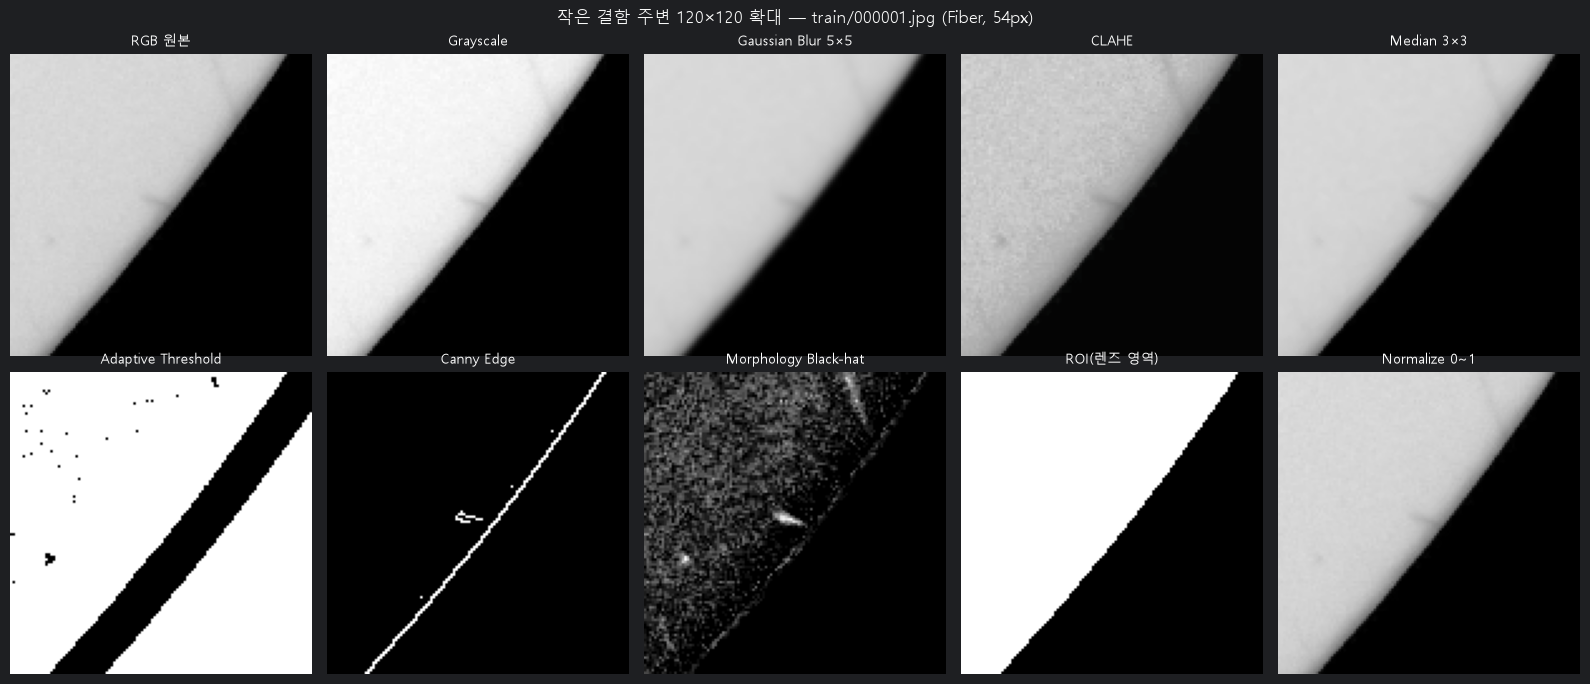

              작은 결함 대비(중앙값)  원본 대비 비율
RGB 원본                9.169     1.000
Gaussian 5×5         14.592     1.591
Median 3×3           13.471     1.469
CLAHE                 5.291     0.577


In [12]:
# 전처리 9가지를 작은 결함 주변 확대 화면에서 눈으로 비교합니다.
def show_transforms(image):
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    roi = valid_region(image)
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15))
    return {"RGB 원본": image, "Grayscale": gray, "Gaussian Blur 5×5": cv2.GaussianBlur(image, (5, 5), 0), "CLAHE": preprocess(image, "clahe"),
            "Median 3×3": preprocess(image, "median"), "Adaptive Threshold": cv2.adaptiveThreshold(gray, 255, cv2.ADAPTIVE_THRESH_MEAN_C, cv2.THRESH_BINARY, 31, 5),
            "Canny Edge": cv2.Canny(gray, 30, 90), "Morphology Black-hat": cv2.normalize(cv2.morphologyEx(gray, cv2.MORPH_BLACKHAT, kernel), None, 0, 255, cv2.NORM_MINMAX),
            "ROI(렌즈 영역)": (roi * 255).astype(np.uint8), "Normalize 0~1": image.astype(np.float32) / 255.0}

key = next(k for k in split_keys("train") if any(i["mask"].sum() < 80 for i in lens_work[k]["instances"]))
inst = min(lens_work[key]["instances"], key=lambda i: i["mask"].sum())
cy, cx = (inst["y0"] + inst["y1"]) // 2, (inst["x0"] + inst["x1"]) // 2
window = lambda a: a[max(0, cy - 60):cy + 60, max(0, cx - 60):cx + 60]
transforms = show_transforms(lens_work[key]["image"])
fig, axes = plt.subplots(2, 5, figsize=(16, 7))
for ax, (name, array) in zip(axes.ravel(), transforms.items()):
    ax.imshow(window(array), cmap="gray" if array.ndim == 2 else None)
    ax.set_title(name, fontsize=10)
    ax.axis("off")
fig.suptitle(f"작은 결함 주변 120×120 확대 — {key} ({LENS_CATEGORIES[inst['category']]}, {int(inst['mask'].sum())}px)")
fig.tight_layout()
fig.savefig(FIG_DIR / "preprocess_comparison_visual.png", dpi=130)
plt.show()

# 작은 결함 대비 보존 정도(train 사진에서 계산)
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15))
methods = {"RGB 원본": lambda im: im, "Gaussian 5×5": lambda im: cv2.GaussianBlur(im, (5, 5), 0), "Median 3×3": lambda im: preprocess(im, "median"), "CLAHE": lambda im: preprocess(im, "clahe")}
contrast = defaultdict(list)
for k in split_keys("train"):
    work = lens_work[k]
    gt, background = work["mask"].astype(bool), work["valid"] & ~cv2.dilate(work["mask"], np.ones((15, 15), np.uint8)).astype(bool)
    for name, fn in methods.items():
        bh = cv2.morphologyEx(cv2.cvtColor(fn(work["image"]), cv2.COLOR_RGB2GRAY), cv2.MORPH_BLACKHAT, kernel).astype(np.float32)
        contrast[name].append(bh[gt].mean() / max(1e-6, bh[background].mean()))
contrast_table = pd.DataFrame({name: [np.median(v), np.median(v) / np.median(contrast["RGB 원본"])] for name, v in contrast.items()}, index=["작은 결함 대비(중앙값)", "원본 대비 비율"]).T
contrast_table.to_csv(MET_DIR / "preprocess_small_defect_contrast.csv", encoding="utf-8-sig")
print(contrast_table.round(3))

## PART 03. Improved CNN 개발
Baseline의 한계를 보완한 구조입니다. 수업의 `Sequential` 방식을 그대로 씁니다.
```
Input(256,256,3) → Rescaling → RandomFlip(학습 때만)
→ Conv2D(16)+BatchNorm+ReLU → Conv2D(16)+ReLU → MaxPool    (256→128)
→ Conv2D(32)+BatchNorm+ReLU → MaxPool                      (128→64)
→ Conv2D(64)+BatchNorm+ReLU
→ GlobalMaxPooling2D        ← 작은 결함의 '가장 강한 반응'을 남김 (Baseline의 평균은 신호가 묽어짐)
→ Dense(64, ReLU) + Dropout → Dense(1, Sigmoid)
```
| 바꾼 점 | 이유 |
|---|---|
| BatchNormalization | 층마다 값 분포를 고르게 해 학습을 안정시킵니다. |
| Conv 2번 + 적은 필터 | 첫 단계에서 세밀한 특징을 더 보고, CPU 계산량은 Baseline보다 줄입니다. |
| GlobalMaxPooling | 구역 안 몇 픽셀짜리 결함 반응이 평균에 묻히지 않게 합니다. |
| Dropout 0.3 | 일부 특징에만 의존하는 과적합을 줄입니다. |

**같은 분할**에서 실험합니다: 전처리(RGB / CLAHE / Median) × 클래스 가중치(사용 / 미사용). **validation AP**가 가장 높은 실험을 `models/lens_cnn_final.keras`로 저장합니다. test는 선택이 끝난 뒤에만 봅니다. 성능이 나아지지 않았다면 나아졌다고 쓰지 않습니다.

이미지 크기 실험은 하지 않았습니다. 입력 256은 지시서 규격이고, 결함 크기는 작업 배율로 이미 맞췄기 때문입니다.

In [13]:
# [TF] 구역 CNN 학습 함수 (저장 모델 재사용 포함) — 두 노트북 공통
def history_figure(history, name):
    metrics = [m for m in ["loss", "accuracy", "pr_auc"] if m in history]
    fig, axes = plt.subplots(1, len(metrics), figsize=(5 * len(metrics), 3.4))
    for ax, metric in zip(np.atleast_1d(axes), metrics):
        ax.plot(history[metric], label="train")
        ax.plot(history["val_" + metric], label="validation")
        ax.set(title=f"{name} — {metric}", xlabel="Epoch", ylabel=metric)
        ax.legend()
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"{name}_history.png", dpi=130)
    plt.show()

def save_architecture(model, name):
    lines = []
    model.summary(print_fn=lines.append)
    (MET_DIR / f"{name}_architecture.txt").write_text("\n".join(lines), encoding="utf-8")
    print("\n".join(lines))

def class_weights_from(labels):
    # 학습 정답 개수만 사용: 적은 쪽(불량 구역) 오차를 더 크게 반영
    counts = np.bincount(labels.astype(int), minlength=2)
    return {c: float(len(labels) / (2 * counts[c])) for c in (0, 1)}

def fit_patch_cnn(name, build_fn, method="rgb", use_class_weight=True, learning_rate=1e-3, epochs=None, extra=None):
    epochs = epochs or CNN_EPOCHS
    X, y, _ = patch_arrays("train", method)
    Xv, yv, _ = patch_arrays("validation", method)
    weights = class_weights_from(y) if use_class_weight else None
    tf.keras.utils.set_random_seed(SEED)
    model = build_fn()
    model.compile(optimizer=keras.optimizers.Adam(learning_rate), loss="binary_crossentropy",
                  metrics=[keras.metrics.BinaryAccuracy(name="accuracy"), keras.metrics.AUC(curve="PR", name="pr_auc"), keras.metrics.Recall(name="recall")])
    signature_value = {"version": "lens-cnn-1.0", "split": SPLIT_SIGNATURE, "patches": PATCH_SIGNATURE, "scale": LENS_SCALE, "patch": PATCH, "stride": STRIDE,
                       "architecture": json.loads(model.to_json()), "method": method, "class_weight": weights, "lr": learning_rate, "epochs": epochs,
                       "batch": BATCH_SIZE, "seed": SEED, "mode": RUN_MODE, "extra": extra}
    signature = hashlib.sha256(json.dumps(signature_value, sort_keys=True, default=str).encode()).hexdigest()
    model_path = MODEL_DIR / f"{name}.keras"
    meta_path = MODEL_DIR / f"{name}.json"
    meta = json.loads(meta_path.read_text(encoding="utf-8")) if meta_path.exists() else {}
    if USE_SAVED_MODELS and model_path.exists() and meta.get("signature") == signature and meta.get("model_sha256") == sha256_file(model_path):
        print(name, "→ 데이터·설정이 같은 저장 모델 재사용")
    else:
        callbacks = [keras.callbacks.EarlyStopping(monitor="val_pr_auc", mode="max", patience=CNN_PATIENCE, restore_best_weights=True),
                     keras.callbacks.ModelCheckpoint(str(model_path), monitor="val_pr_auc", mode="max", save_best_only=True),
                     keras.callbacks.CSVLogger(str(MET_DIR / f"{name}_history.csv"))]
        started = time.perf_counter()
        history = model.fit(X, y, validation_data=(Xv, yv), class_weight=weights, batch_size=BATCH_SIZE, epochs=epochs, callbacks=callbacks, verbose=2)
        meta = {"signature": signature, "name": name, "task": "lens_patch_binary(0=정상 구역,1=불량 구역)", "method": method, "class_weight": weights,
                "learning_rate": learning_rate, "parameters": int(model.count_params()), "training_seconds": time.perf_counter() - started,
                "epochs_completed": len(history.history["loss"]), "history": {k: [float(v) for v in vals] for k, vals in history.history.items()},
                "model_sha256": sha256_file(model_path), "model_bytes": model_path.stat().st_size, "checkpoint_monitor": "val_pr_auc",
                "train_patches": int(len(y)), "train_defect_patches": int(y.sum()), "extra": extra, "score_is_calibrated_probability": False}
        save_architecture(model, name)
        history_figure(meta["history"], name)
        save_json(meta_path, meta)
    model = keras.models.load_model(model_path, compile=False)  # 저장 파일로만 평가·추론
    def predict_fn(batch):
        out = []
        for start in range(0, len(batch), 64):
            out.append(model(batch[start:start + 64].astype(np.float32), training=False).numpy().reshape(-1))
        return np.concatenate(out) if out else np.zeros(0, np.float32)
    return {"name": name, "model": model, "meta": meta, "meta_path": meta_path, "model_path": model_path, "predict": predict_fn, "method": method}

In [14]:
# [TF] CNN 구조 — Baseline(01과 동일)과 Improved
def build_baseline_cnn():
    model = keras.Sequential(name="lens_cnn_baseline")
    model.add(layers.Input((IMAGE_SIZE, IMAGE_SIZE, 3), name="image"))
    model.add(layers.Rescaling(1.0 / 255.0, name="normalize"))
    model.add(layers.RandomFlip("horizontal_and_vertical", seed=SEED, name="train_flip"))
    model.add(layers.Conv2D(32, 3, padding="same", activation="relu", name="conv1"))
    model.add(layers.MaxPooling2D(name="pool1"))
    model.add(layers.Conv2D(64, 3, padding="same", activation="relu", name="conv2"))
    model.add(layers.MaxPooling2D(name="pool2"))
    model.add(layers.Conv2D(128, 3, padding="same", activation="relu", name="conv3"))
    model.add(layers.GlobalAveragePooling2D(name="gap"))
    model.add(layers.Dense(64, activation="relu", name="dense"))
    model.add(layers.Dense(1, activation="sigmoid", name="defect_score"))
    return model

def build_improved_cnn(dropout=0.3):
    model = keras.Sequential(name="lens_cnn_improved")
    model.add(layers.Input((IMAGE_SIZE, IMAGE_SIZE, 3), name="image"))
    model.add(layers.Rescaling(1.0 / 255.0, name="normalize"))
    model.add(layers.RandomFlip("horizontal_and_vertical", seed=SEED, name="train_flip"))
    model.add(layers.Conv2D(16, 3, padding="same", use_bias=False, name="conv1a"))
    model.add(layers.BatchNormalization(name="bn1"))
    model.add(layers.Activation("relu", name="relu1a"))
    model.add(layers.Conv2D(16, 3, padding="same", activation="relu", name="conv1b"))
    model.add(layers.MaxPooling2D(name="pool1"))
    model.add(layers.Conv2D(32, 3, padding="same", use_bias=False, name="conv2"))
    model.add(layers.BatchNormalization(name="bn2"))
    model.add(layers.Activation("relu", name="relu2"))
    model.add(layers.MaxPooling2D(name="pool2"))
    model.add(layers.Conv2D(64, 3, padding="same", use_bias=False, name="conv3"))
    model.add(layers.BatchNormalization(name="bn3"))
    model.add(layers.Activation("relu", name="relu3"))
    model.add(layers.GlobalMaxPooling2D(name="gmp"))
    model.add(layers.Dense(64, activation="relu", name="dense"))
    model.add(layers.Dropout(dropout, name="dropout"))
    model.add(layers.Dense(1, activation="sigmoid", name="defect_score"))
    return model

build_improved_cnn().summary()



Model: "lens_cnn_improved"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 normalize (Rescaling)       (None, 256, 256, 3)       0         
                                                                 
 train_flip (RandomFlip)     (None, 256, 256, 3)       0         
                                                                 
 conv1a (Conv2D)             (None, 256, 256, 16)      432       
                                                                 
 bn1 (BatchNormalization)    (None, 256, 256, 16)      64        
                                                                 
 relu1a (Activation)         (None, 256, 256, 16)      0         
                                                                 
 conv1b (Conv2D)             (None, 256, 256, 16)      2320      
                                                                 
 pool1 (MaxPooling2D)        (None, 128, 128, 1

In [15]:
# Baseline 확보(01의 저장 모델을 재사용, 없으면 여기서 학습) + Improved 실험을 validation으로 비교
def evaluate_on(run, split):
    X, y, rows = patch_arrays(split, run["method"])
    started = time.perf_counter()
    scores = run["predict"](X)
    return y, scores, rows, time.perf_counter() - started

def freeze_thresholds(run):
    yv, sv, _, _ = evaluate_on(run, "validation")
    ng = threshold_for_recall(yv, sv, RECALL_TARGET)
    run.update({"ng": ng, "ok_upper": min(ng, threshold_for_recall(yv, sv, REVIEW_RECALL)), "val_metrics": binary_metrics(yv, sv, ng), "val_ap": float(average_precision_score(yv, sv))})
    return run

baseline_run = freeze_thresholds(fit_patch_cnn("lens_cnn_baseline", build_baseline_cnn, method="rgb", use_class_weight=False, learning_rate=LEARNING_RATE))
experiment_runs, rows = {}, []
if TRAIN_IMPROVED_CNN:
    for exp in CNN_EXPERIMENTS:
        run = freeze_thresholds(fit_patch_cnn(f"lens_cnn_exp_{exp['id']}", lambda d=exp["dropout"]: build_improved_cnn(d), method=exp["method"],
                                              use_class_weight=exp["class_weight"], learning_rate=exp["lr"], extra=exp))
        experiment_runs[exp["id"]] = run
for name, run in [("baseline", baseline_run)] + list(experiment_runs.items()):
    m = run["val_metrics"]
    rows.append({"실험": name, "전처리": run["method"], "val_AP": run["val_ap"], "val_ROC_AUC": m["roc_auc"], "val_Recall@NG": m["recall"], "val_Precision@NG": m["precision"],
                 "val_FPR@NG": m["false_positive_rate"], "NG경계": run["ng"], "학습초": run["meta"].get("training_seconds"), "epoch": run["meta"].get("epochs_completed")})
experiment_table = pd.DataFrame(rows)
experiment_table.to_csv(MET_DIR / "lens_cnn_experiments_validation.csv", index=False, encoding="utf-8-sig")
print(experiment_table.round(4))

candidates = {**({"baseline": baseline_run} if not experiment_runs else {}), **experiment_runs}
best_id = max(candidates, key=lambda k: candidates[k]["val_ap"])
final_run = candidates[best_id]
print("validation AP 기준 최종 선택:", best_id, "/ Baseline 대비 val AP", round(final_run["val_ap"] - baseline_run["val_ap"], 4))

# 선택한 모델을 지시서 이름으로 저장(복사)하고 설정을 함께 기록
final_path = MODEL_DIR / "lens_cnn_final.keras"
shutil.copy2(final_run["model_path"], final_path)
FINAL_MODEL_SHA = sha256_file(final_path)
FINAL_MODEL_VERSION = f"lens_cnn_final-{MODEL_VERSION_TAG}-{FINAL_MODEL_SHA[:8]}"
save_json(MODEL_DIR / "lens_cnn_final.json", {"selected_experiment": best_id, "source_model": final_run["model_path"].name, "method": final_run["method"],
                                               "ok_upper_threshold": final_run["ok_upper"], "ng_threshold": final_run["ng"], "validation_ap": final_run["val_ap"],
                                               "model_sha256": FINAL_MODEL_SHA, "model_version": FINAL_MODEL_VERSION, "split_signature": SPLIT_SIGNATURE, "mode": RUN_MODE})

lens_cnn_baseline → 데이터·설정이 같은 저장 모델 재사용
lens_cnn_exp_rgb_cw → 데이터·설정이 같은 저장 모델 재사용
lens_cnn_exp_clahe_cw → 데이터·설정이 같은 저장 모델 재사용
lens_cnn_exp_median_cw → 데이터·설정이 같은 저장 모델 재사용
lens_cnn_exp_rgb_nocw → 데이터·설정이 같은 저장 모델 재사용
          실험     전처리  val_AP  val_ROC_AUC  val_Recall@NG  val_Precision@NG  \
0   baseline     rgb  0.3147       0.7060         0.9716            0.2295   
1     rgb_cw     rgb  0.3492       0.7389         0.9574            0.2304   
2   clahe_cw   clahe  0.2990       0.7277         0.9504            0.2283   
3  median_cw  median  0.3192       0.7436         0.9504            0.2459   
4   rgb_nocw     rgb  0.3120       0.7348         0.9504            0.2428   

   val_FPR@NG    NG경계        학습초  epoch  
0      0.6917  0.3781   782.8306     17  
1      0.6782  0.2865  1128.5769     20  
2      0.6812  0.3907   241.7573      8  
3      0.6180  0.2723   502.3958     18  
4      0.6286  0.1706   555.9763     20  
validation AP 기준 최종 선택: rgb_cw / Baseline 대비 val AP 0.0344


                           0                     1
모델              CNN Baseline  Improved CNN (Final)
전처리                      rgb                   rgb
Accuracy            0.421701              0.443402
Precision           0.221289               0.22348
Recall              0.955095              0.920553
F1                  0.359324              0.359649
ROC-AUC             0.684424              0.755983
AP                  0.272416              0.418667
FN(구역)                    26                    46
FP(구역)                  1946                  1852
구역 FPR               0.68739              0.654186
사진 자동NG Recall           1.0                   1.0
사진 REVIEW                  0                     0
OK로 통과된 불량 사진              0                     0
학습 시간(초)          782.830565           1128.576856
추론 ms/사진          556.468506            319.033887
모델 크기(MB)           1.273569              0.445458
파라미터                  101569                 30465


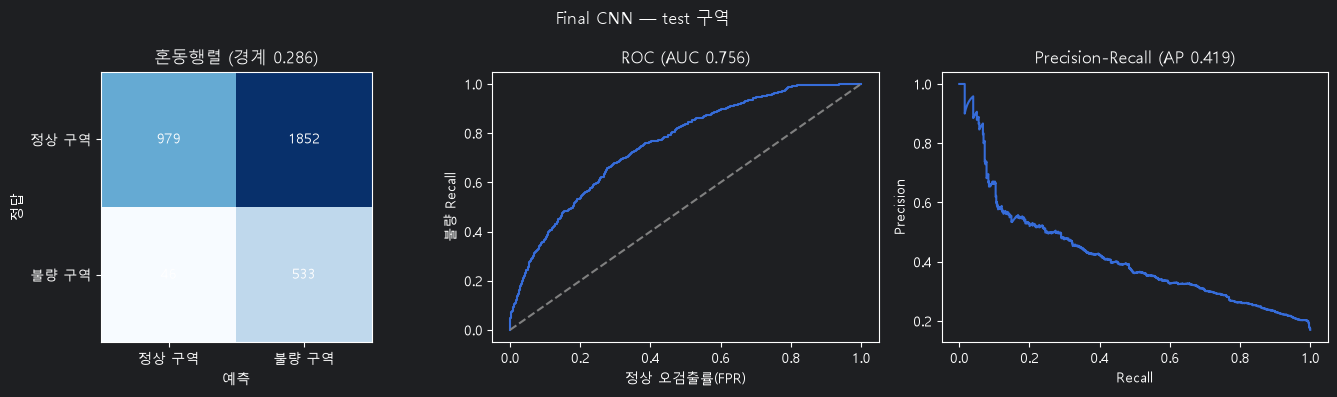

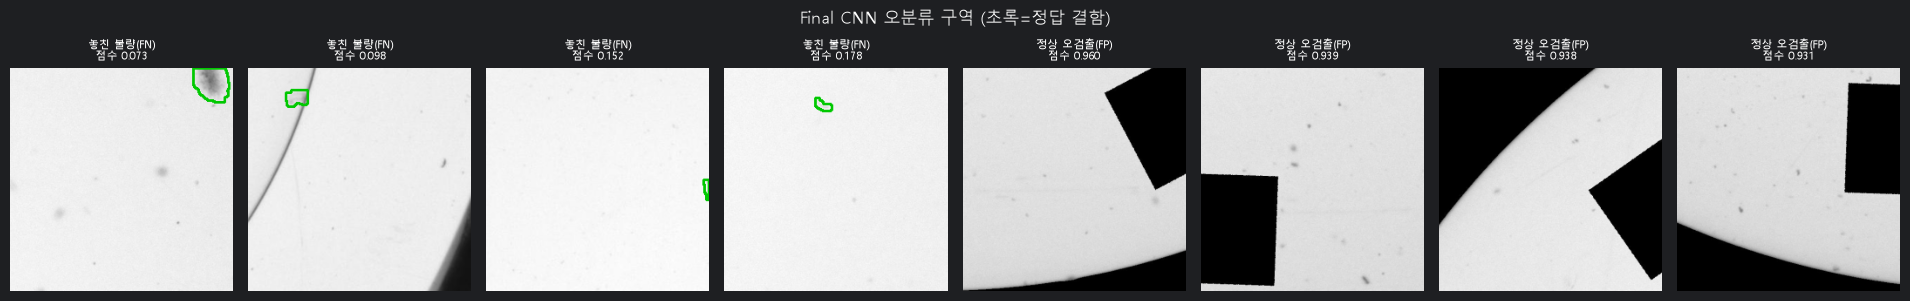

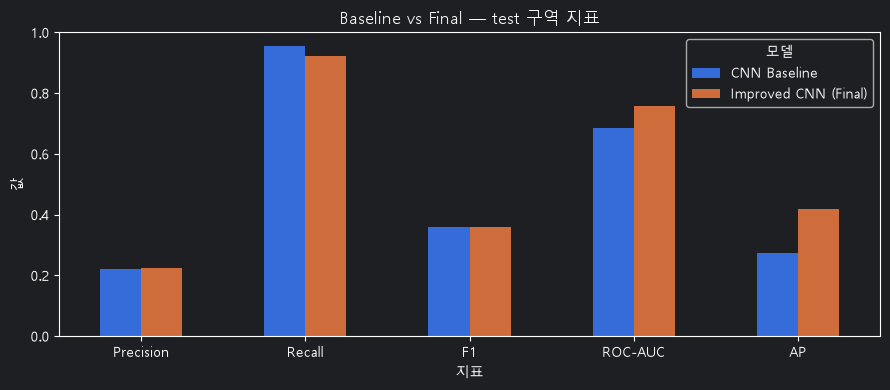

In [16]:
# 선택이 끝난 뒤 test 평가: Baseline vs Final (같은 test 구역)
compare_rows, test_results = [], {}
for label, run in [("CNN Baseline", baseline_run), ("Improved CNN (Final)", final_run)]:
    yt, st, rt, sec = evaluate_on(run, "test")
    metrics = binary_metrics(yt, st, run["ng"])
    img = image_level_summary(image_scores(rt, st), run["ok_upper"], run["ng"])
    test_results[label] = {"run": run, "y": yt, "scores": st, "rows": rt, "metrics": metrics, "image": img, "seconds": sec}
    compare_rows.append({"모델": label, "전처리": run["method"], "Accuracy": metrics["accuracy"], "Precision": metrics["precision"], "Recall": metrics["recall"], "F1": metrics["f1"],
                         "ROC-AUC": metrics["roc_auc"], "AP": metrics["average_precision"], "FN(구역)": metrics["FN"], "FP(구역)": metrics["FP"], "구역 FPR": metrics["false_positive_rate"],
                         "사진 자동NG Recall": img["auto_ng_recall"], "사진 REVIEW": img["REVIEW"], "OK로 통과된 불량 사진": img["defect_passed_as_ok"],
                         "학습 시간(초)": run["meta"].get("training_seconds"), "추론 ms/사진": 1000 * sec / max(1, img["images"]),
                         "모델 크기(MB)": run["model_path"].stat().st_size / 1e6, "파라미터": run["meta"].get("parameters")})
cnn_comparison = pd.DataFrame(compare_rows)
cnn_comparison.to_csv(MET_DIR / "lens_cnn_baseline_vs_final_test.csv", index=False, encoding="utf-8-sig")
print(cnn_comparison.T)
final_test = test_results["Improved CNN (Final)"]
plot_evaluation(final_test["y"], final_test["scores"], final_run["ng"], "Final CNN — test 구역", FIG_DIR / "final_cnn_evaluation.png")
plot_patch_mistakes(final_test["rows"], final_test["scores"], final_run["ng"], final_run["method"], "Final CNN 오분류 구역 (초록=정답 결함)", FIG_DIR / "final_cnn_mistakes.png")
fig, ax = plt.subplots(figsize=(9, 4))
cnn_comparison.set_index("모델")[["Precision", "Recall", "F1", "ROC-AUC", "AP"]].T.plot.bar(ax=ax)
ax.set(title="Baseline vs Final — test 구역 지표", xlabel="지표", ylabel="값", ylim=(0, 1))
ax.tick_params(axis="x", rotation=0)
fig.tight_layout()
fig.savefig(FIG_DIR / "cnn_baseline_vs_final.png", dpi=130)
plt.show()

## PART 04. U-Net 결함 위치 분할
**먼저 마스크 품질을 확인합니다.** VISION의 polygon은 원래 bbox 주석을 보완해서 그린 것입니다. 그래서 실제 결함 경계와 꼭 일치한다고 가정하지 않습니다.
- **눈으로 확인:** 종류별 결함을 확대해 polygon이 결함을 잘 감싸는지 봅니다.
- **숫자로 확인:**
  - polygon 넓이 ÷ bbox 넓이 — 너무 작으면 선 하나, 1에 가까우면 사각형에 가까움
  - COCO area와 polygon 넓이의 차이
- 두 확인을 통과해야(`UNET_MASK_TRUSTED`) 분할 학습을 진행합니다. 통과하지 못하면 약지도 실험으로 표시합니다.

**구조 (직접 작성, Keras Functional API):** U-Net은 인코더 출력을 디코더에 이어 붙여야(skip connection) 해서, 한 줄로 쌓는 `Sequential`로는 만들 수 없습니다.
```
입력 256×256×3 → Encoder1(16) → Encoder2(32) → Encoder3(64) → Bottleneck(128)
→ Decoder3(64)+skip3 → Decoder2(32)+skip2 → Decoder1(16)+skip1 → 1×1 Conv + Sigmoid → 결함 마스크 256×256×1
```
- **손실 비교:** BCE / BCE+Dice. 결함 픽셀이 0.2% 정도라 BCE만 쓰면 '전부 배경'으로 쏠릴 수 있습니다.
- **증강:** 사진과 마스크를 붙여 **같은** 뒤집기·90° 회전을 줍니다(train만).
- **평가:** 검증으로 마스크 경계를 정하고, test 사진 전체를 sliding window로 예측합니다. 지표는 Dice·IoU·Pixel Precision·Pixel Recall입니다.

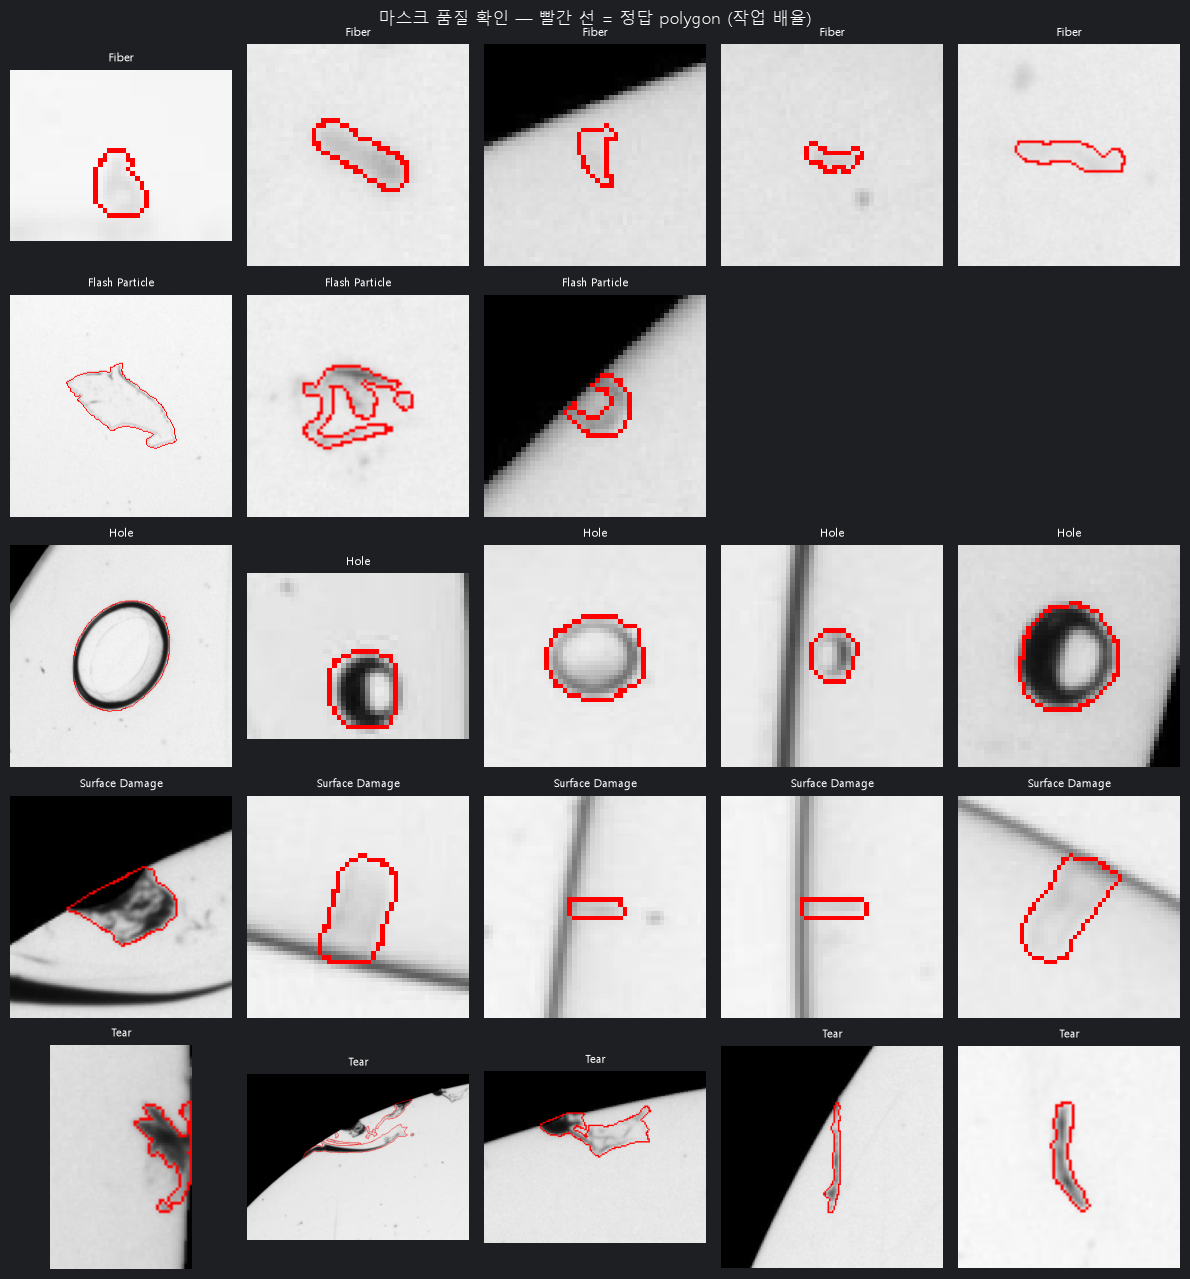

                polygon_fill_of_bbox  area_gap
category                                      
Fiber                          0.427       0.0
Flash Particle                 0.478       0.0
Hole                           0.802       0.0
Surface Damage                 0.620       0.0
Tear                           0.305       0.0
마스크 사용 판단(UNET_MASK_TRUSTED): True — 그림을 보고 polygon이 결함을 감싸지 않으면 False로 바꾸세요.


In [17]:
# 마스크 품질 확인 (눈 + 숫자)
fig, axes = plt.subplots(len(LENS_CATEGORIES), 5, figsize=(12, 2.6 * len(LENS_CATEGORIES)))
for row_axes, (cid, name) in zip(axes, enumerate(LENS_CATEGORIES)):
    found = [(k, i) for k in split_keys("train") for i in lens_work[k]["instances"] if i["category"] == cid][:5]
    for ax in row_axes:
        ax.axis("off")
    for ax, (k, i) in zip(row_axes, found):
        image = lens_work[k]["image"].copy()
        cv2.polylines(image, i["points"], True, (255, 0, 0), 1)
        cy, cx = (i["y0"] + i["y1"]) // 2, (i["x0"] + i["x1"]) // 2
        half = max(24, (i["y1"] - i["y0"]), (i["x1"] - i["x0"]))
        ax.imshow(image[max(0, cy - half):cy + half, max(0, cx - half):cx + half])
        ax.set_title(name, fontsize=8)
fig.suptitle("마스크 품질 확인 — 빨간 선 = 정답 polygon (작업 배율)")
fig.tight_layout()
fig.savefig(FIG_DIR / "unet_mask_quality_check.png", dpi=130)
plt.show()
quality = lens_instances[lens_instances.split == "train"].assign(area_gap=lambda d: (d.coco_area / d.polygon_area.clip(lower=1) - 1).abs())
quality_table = quality.groupby("category")[["polygon_fill_of_bbox", "area_gap"]].median().round(3)
print(quality_table)
UNET_MASK_TRUSTED = bool(quality.area_gap.median() < 0.2 and quality.polygon_fill_of_bbox.median() > 0.2)
print("마스크 사용 판단(UNET_MASK_TRUSTED):", UNET_MASK_TRUSTED, "— 그림을 보고 polygon이 결함을 감싸지 않으면 False로 바꾸세요.")

In [18]:
# 위치 지표·sliding window 예측 도구 (TensorFlow 불필요)
from scipy import ndimage

def predict_full(predict_fn, image, batch_size=16):
    height, width = image.shape[:2]
    padded = pad_to(image)
    total = np.zeros(padded.shape[:2], np.float32)
    count = np.zeros(padded.shape[:2], np.float32)
    positions = [(y, x) for y in grid_starts(padded.shape[0]) for x in grid_starts(padded.shape[1])]
    for start in range(0, len(positions), batch_size):
        chunk = positions[start:start + batch_size]
        scores = predict_fn(np.stack([padded[y:y + PATCH, x:x + PATCH] for y, x in chunk]))
        for (y, x), score in zip(chunk, scores):
            total[y:y + PATCH, x:x + PATCH] += score
            count[y:y + PATCH, x:x + PATCH] += 1
    return (total / np.maximum(count, 1))[:height, :width]

def binarize(score_map, threshold, min_blob=UNET_MIN_BLOB_PX):
    mask = (score_map >= threshold).astype(np.uint8)
    count, labels, stats, _ = cv2.connectedComponentsWithStats(mask, connectivity=8)
    keep = stats[:, cv2.CC_STAT_AREA] >= min_blob
    keep[0] = False
    return keep[labels].astype(np.uint8)

def segmentation_metrics(keys, score_maps, threshold):
    rows, totals = [], Counter()
    for key in keys:
        work = lens_work[key]
        gt = work["mask"].astype(bool)
        pred = binarize(score_maps[key].astype(np.float32), threshold).astype(bool)
        tp, fp, fn = int((gt & pred).sum()), int((~gt & pred).sum()), int((gt & ~pred).sum())
        totals.update({"tp": tp, "fp": fp, "fn": fn})
        found = sum(bool(pred[i["y0"]:i["y1"], i["x0"]:i["x1"]][i["mask"]].any()) for i in work["instances"])
        count, labels, stats, _ = cv2.connectedComponentsWithStats(pred.astype(np.uint8), connectivity=8)
        touching = np.bincount(labels[gt], minlength=count) > 0
        outside = [i for i in range(1, count) if not touching[i]]
        rows.append({"image_key": key, "group": work["group"], "dice": 2 * tp / max(1, 2 * tp + fp + fn), "iou": tp / max(1, tp + fp + fn),
                     "instances": len(work["instances"]), "instances_found": found, "blobs_outside_gt": len(outside)})
    frame = pd.DataFrame(rows)
    tp, fp, fn = totals["tp"], totals["fp"], totals["fn"]
    return {"threshold": threshold, "images": len(keys), "defect_image_mean_dice": float(frame.dice.mean()), "defect_image_mean_iou": float(frame.iou.mean()),
            "pixel_dice": 2 * tp / max(1, 2 * tp + fp + fn), "pixel_iou": tp / max(1, tp + fp + fn), "pixel_precision": tp / max(1, tp + fp), "pixel_recall": tp / max(1, tp + fn),
            "instance_recall": float(frame.instances_found.sum() / max(1, frame.instances.sum())), "blobs_outside_gt_per_image": float(frame.blobs_outside_gt.mean()),
            "normal_image_false_area": None, "normal_image_false_area_reason": "공식 정상 사진 0장"}, frame

def choose_threshold(keys, score_maps):
    table = pd.DataFrame([{k: v for k, v in segmentation_metrics(keys, score_maps, t)[0].items() if isinstance(v, (int, float))} for t in UNET_THRESHOLDS])
    best = table.sort_values(["defect_image_mean_dice", "threshold"], ascending=False).iloc[0]
    return float(best.threshold), table

def overlay_image(image, gt, pred):
    # 초록=정답만, 빨강=예측만, 노랑=겹침. 작은 결함도 보이게 굵은 테두리를 함께 그립니다.
    canvas = image.astype(np.float32).copy()
    pred = pred.astype(bool)
    regions = [(pred, (255, 0, 0))] if gt is None else [(gt.astype(bool) & ~pred, (0, 200, 0)), (~gt.astype(bool) & pred, (255, 0, 0)), (gt.astype(bool) & pred, (255, 220, 0))]
    for region, color in regions:
        canvas[region] = 0.35 * canvas[region] + 0.65 * np.array(color, np.float32)
    canvas = canvas.astype(np.uint8)
    for region, color in [(pred, (255, 0, 0))] + ([(gt.astype(bool), (0, 200, 0))] if gt is not None else []):
        contours, _ = cv2.findContours(cv2.dilate(region.astype(np.uint8), np.ones((9, 9), np.uint8)), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        cv2.drawContours(canvas, contours, -1, color, 2)
    return canvas

# 학습 없는 기준선(Black-hat 규칙): U-Net이 넘어야 할 최소 기준
BLACKHAT_KERNEL = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15))
def blackhat_predict(batch):
    return np.stack([np.clip(cv2.morphologyEx(cv2.cvtColor(p.astype(np.uint8), cv2.COLOR_RGB2GRAY), cv2.MORPH_BLACKHAT, BLACKHAT_KERNEL) / 40.0, 0, 1).astype(np.float32) for p in batch])
val_keys, test_keys = split_keys("validation"), split_keys("test")
rule_val = {k: predict_full(blackhat_predict, lens_work[k]["image"]).astype(np.float16) for k in val_keys}
RULE_THRESHOLD, _ = choose_threshold(val_keys, rule_val)
rule_validation = segmentation_metrics(val_keys, rule_val, RULE_THRESHOLD)[0]
rule_test = segmentation_metrics(test_keys, {k: predict_full(blackhat_predict, lens_work[k]["image"]).astype(np.float16) for k in test_keys}, RULE_THRESHOLD)[0]
save_json(MET_DIR / "lens_rule_baseline_segmentation.json", {"threshold": RULE_THRESHOLD, "validation": rule_validation, "test_reference_only": rule_test})
print("규칙 기준선 validation 평균 Dice:", round(rule_validation["defect_image_mean_dice"], 4), "/ 정답 밖 덩어리/사진:", round(rule_validation["blobs_outside_gt_per_image"], 1))

규칙 기준선 validation 평균 Dice: 0.1478 / 정답 밖 덩어리/사진: 180.9


In [19]:
# [TF] U-Net 구조·손실·학습 함수 (핵심 코드)
def augment_pair(image, mask):
    both = tf.concat([tf.cast(image, tf.float32), tf.cast(mask, tf.float32)], axis=-1)  # 사진+마스크를 붙여 같은 변환
    both = tf.image.random_flip_left_right(both)
    both = tf.image.random_flip_up_down(both)
    both = tf.image.rot90(both, k=tf.random.uniform([], 0, 4, dtype=tf.int32))
    image, mask = both[..., :3], both[..., 3:]
    image = image * tf.random.uniform([], 0.9, 1.1) + tf.random.uniform([], -10.0, 10.0)  # 밝기·대비는 사진에만
    return tf.clip_by_value(image, 0.0, 255.0), mask

def conv_block(x, filters, name):
    for i in range(2):
        x = layers.Conv2D(filters, 3, padding="same", use_bias=False, name=f"{name}_conv{i}")(x)
        x = layers.BatchNormalization(name=f"{name}_bn{i}")(x)
        x = layers.Activation("relu", name=f"{name}_relu{i}")(x)
    return x

def build_unet(filters=UNET_FILTERS):
    inputs = keras.Input((IMAGE_SIZE, IMAGE_SIZE, 3), name="image")
    x = layers.Rescaling(1.0 / 255.0, name="normalize")(inputs)
    skips = []
    for i, f in enumerate(filters[:-1]):  # Encoder 1·2·3
        x = conv_block(x, f, f"encoder{i + 1}")
        skips.append(x)
        x = layers.MaxPooling2D(name=f"pool{i + 1}")(x)
    x = conv_block(x, filters[-1], "bottleneck")
    for i in reversed(range(len(filters) - 1)):  # Decoder 3·2·1
        x = layers.Conv2DTranspose(filters[i], 2, strides=2, padding="same", name=f"up{i + 1}")(x)
        x = layers.Concatenate(name=f"skip{i + 1}")([x, skips[i]])
        x = conv_block(x, filters[i], f"decoder{i + 1}")
    outputs = layers.Conv2D(1, 1, activation="sigmoid", name="defect_mask")(x)
    return keras.Model(inputs, outputs, name="lens_unet")

def dice_coef(y_true, y_pred, smooth=1.0):
    y_true = tf.cast(y_true, tf.float32)
    return (2.0 * tf.reduce_sum(y_true * y_pred) + smooth) / (tf.reduce_sum(y_true) + tf.reduce_sum(y_pred) + smooth)
_bce = keras.losses.BinaryCrossentropy()
def bce_loss(y_true, y_pred):
    return _bce(tf.cast(y_true, tf.float32), y_pred)
def bce_dice_loss(y_true, y_pred):
    return bce_loss(y_true, y_pred) + (1.0 - dice_coef(y_true, y_pred))
UNET_LOSS_FUNCTIONS = {"bce": bce_loss, "bce_dice": bce_dice_loss}

def unet_arrays(split):
    X, _, rows = patch_arrays(split, "rgb")
    Y = np.stack([pad_to(lens_work[r.image_key]["mask"])[r.y:r.y + PATCH, r.x:r.x + PATCH, None] for r in rows.itertuples()]).astype(np.uint8)
    return X, Y

def fit_unet(loss_name):
    name = f"lens_unet_{loss_name}"
    tf.keras.utils.set_random_seed(SEED)
    model = build_unet()
    signature_value = {"version": "lens-unet-1.0", "split": SPLIT_SIGNATURE, "patches": PATCH_SIGNATURE, "scale": LENS_SCALE, "architecture": json.loads(model.to_json()),
                       "loss": loss_name, "epochs": UNET_EPOCHS, "batch": BATCH_SIZE, "seed": SEED, "mode": RUN_MODE}
    signature = hashlib.sha256(json.dumps(signature_value, sort_keys=True).encode()).hexdigest()
    model_path, meta_path = MODEL_DIR / f"{name}.keras", MODEL_DIR / f"{name}.json"
    meta = json.loads(meta_path.read_text(encoding="utf-8")) if meta_path.exists() else {}
    if USE_SAVED_MODELS and model_path.exists() and meta.get("signature") == signature and meta.get("model_sha256") == sha256_file(model_path):
        print(name, "→ 저장 모델 재사용")
    else:
        X, Y = unet_arrays("train")
        Xv, Yv = unet_arrays("validation")
        train_ds = tf.data.Dataset.from_tensor_slices((X, Y)).shuffle(len(X), seed=SEED).map(augment_pair, num_parallel_calls=tf.data.AUTOTUNE).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
        val_ds = tf.data.Dataset.from_tensor_slices((Xv.astype(np.float32), Yv.astype(np.float32))).batch(BATCH_SIZE)
        model.compile(optimizer=keras.optimizers.Adam(LEARNING_RATE), loss=UNET_LOSS_FUNCTIONS[loss_name], metrics=[dice_coef])
        callbacks = [keras.callbacks.EarlyStopping(monitor="val_dice_coef", mode="max", patience=UNET_PATIENCE, restore_best_weights=True),
                     keras.callbacks.ModelCheckpoint(str(model_path), monitor="val_dice_coef", mode="max", save_best_only=True),
                     keras.callbacks.CSVLogger(str(MET_DIR / f"{name}_history.csv"))]
        started = time.perf_counter()
        history = model.fit(train_ds, validation_data=val_ds, epochs=UNET_EPOCHS, callbacks=callbacks, verbose=2)
        meta = {"signature": signature, "name": name, "loss": loss_name, "parameters": int(model.count_params()), "training_seconds": time.perf_counter() - started,
                "epochs_completed": len(history.history["loss"]), "history": {k: [float(v) for v in vals] for k, vals in history.history.items()},
                "model_sha256": sha256_file(model_path), "model_bytes": model_path.stat().st_size}
        lines = []
        model.summary(print_fn=lines.append)
        (MET_DIR / f"{name}_architecture.txt").write_text("\n".join(lines), encoding="utf-8")
        fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
        for ax, metric in zip(axes, ["loss", "dice_coef"]):
            ax.plot(meta["history"][metric], label="train")
            ax.plot(meta["history"]["val_" + metric], label="validation")
            ax.set(title=f"{name} — {metric}", xlabel="Epoch", ylabel=metric)
            ax.legend()
        fig.tight_layout()
        fig.savefig(FIG_DIR / f"{name}_history.png", dpi=130)
        plt.show()
        save_json(meta_path, meta)
    model = keras.models.load_model(model_path, compile=False)
    def predict_fn(batch):
        return model(batch.astype(np.float32), training=False).numpy()[..., 0]
    return {"name": name, "model": model, "meta": meta, "meta_path": meta_path, "model_path": model_path, "predict": predict_fn}

lens_unet_bce → 저장 모델 재사용
lens_unet_bce_dice → 저장 모델 재사용
                                        0                   1
model                       lens_unet_bce  lens_unet_bce_dice
loss                                  bce            bce_dice
val_threshold                        0.15                0.25
threshold                            0.15                0.25
defect_image_mean_dice             0.2706              0.2874
defect_image_mean_iou              0.1938              0.2003
pixel_dice                         0.5398              0.3633
pixel_iou                          0.3697               0.222
pixel_precision                    0.4319              0.3557
pixel_recall                       0.7198              0.3713
instance_recall                    0.2985              0.4627
blobs_outside_gt_per_image         7.4375              9.0625
train_seconds                  14764.4916           7427.4998
epochs                                 25                  20
선택: lens_unet

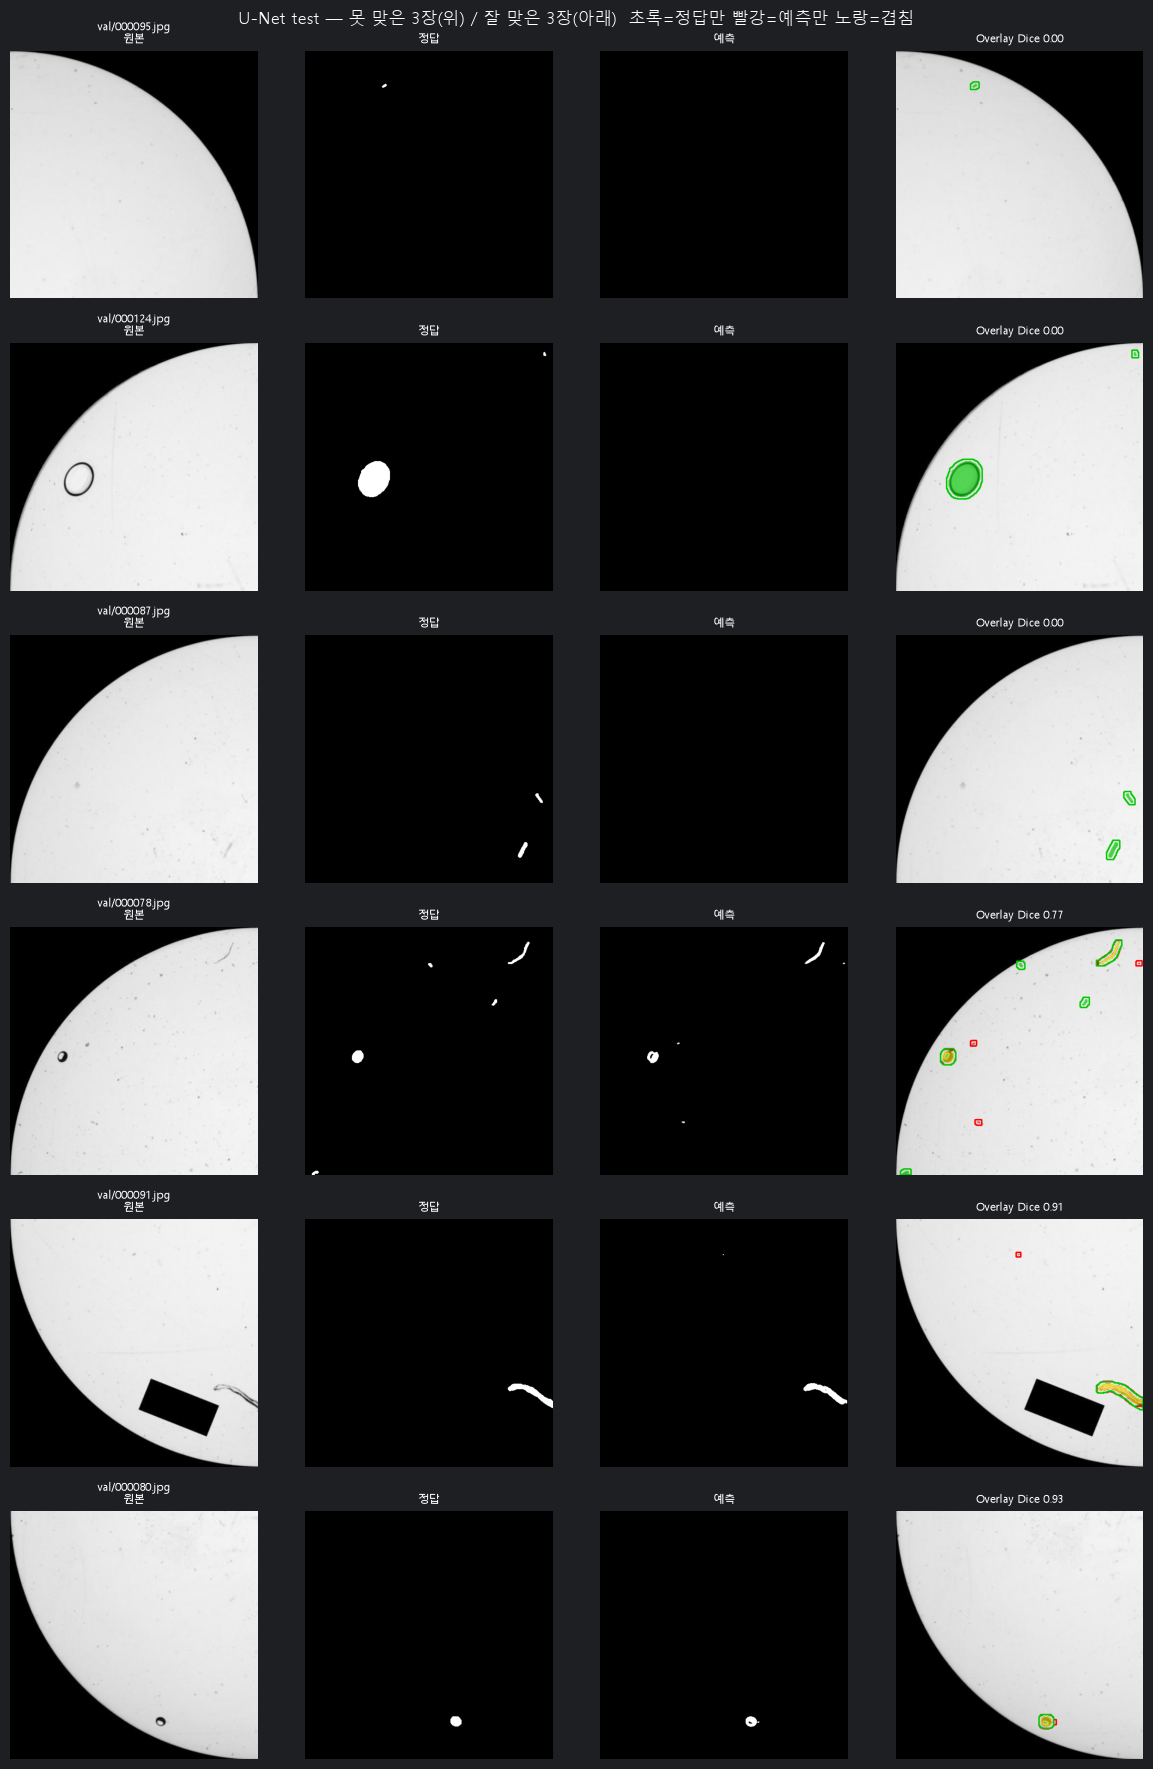

In [20]:
# U-Net 학습 → validation으로 손실·경계 선택 → test 1회 평가 → lens_unet.keras 저장
unet_runs, unet_rows, UNET_FINAL = {}, [], None
if TRAIN_UNET and UNET_MASK_TRUSTED:
    for loss_name in UNET_LOSSES:
        run = fit_unet(loss_name)
        run["val_scores"] = {k: predict_full(run["predict"], lens_work[k]["image"]).astype(np.float16) for k in val_keys}
        run["threshold"], table = choose_threshold(val_keys, run["val_scores"])
        table.to_csv(MET_DIR / f"{run['name']}_validation_thresholds.csv", index=False, encoding="utf-8-sig")
        run["val_summary"] = segmentation_metrics(val_keys, run["val_scores"], run["threshold"])[0]
        unet_runs[loss_name] = run
        unet_rows.append({"model": run["name"], "loss": loss_name, "val_threshold": run["threshold"], **{k: v for k, v in run["val_summary"].items() if isinstance(v, float)},
                          "train_seconds": run["meta"].get("training_seconds"), "epochs": run["meta"].get("epochs_completed")})
    unet_table = pd.DataFrame(unet_rows)
    unet_table.to_csv(MET_DIR / "lens_unet_validation_comparison.csv", index=False, encoding="utf-8-sig")
    UNET_FINAL = unet_runs[unet_table.sort_values("defect_image_mean_dice", ascending=False).iloc[0].loss]
    UNET_EXPERIMENTAL = bool(UNET_FINAL["val_summary"]["defect_image_mean_dice"] < UNET_EXPERIMENTAL_DICE)
    shutil.copy2(UNET_FINAL["model_path"], MODEL_DIR / "lens_unet.keras")
    started = time.perf_counter()
    unet_test_scores = {k: predict_full(UNET_FINAL["predict"], lens_work[k]["image"]).astype(np.float16) for k in test_keys}
    unet_ms = 1000 * (time.perf_counter() - started) / max(1, len(test_keys))
    unet_test, unet_test_images = segmentation_metrics(test_keys, unet_test_scores, UNET_FINAL["threshold"])
    unet_test.update({"model": UNET_FINAL["name"], "inference_ms_per_image": unet_ms, "experimental": UNET_EXPERIMENTAL})
    save_json(MET_DIR / "lens_unet_test_metrics.json", unet_test)
    save_json(MODEL_DIR / "lens_unet.json", {"source_model": UNET_FINAL["model_path"].name, "loss": UNET_FINAL["meta"].get("loss"), "threshold": UNET_FINAL["threshold"],
                                            "experimental": UNET_EXPERIMENTAL, "model_sha256": sha256_file(MODEL_DIR / "lens_unet.keras")})
    unet_test_images.to_csv(PRED_DIR / "lens_unet_test_per_image.csv", index=False, encoding="utf-8-sig")
    print(unet_table.round(4).T)
    print("선택:", UNET_FINAL["name"], "/ 경계", UNET_FINAL["threshold"], "/ 실험용 표시:", UNET_EXPERIMENTAL)
    print({k: round(v, 4) for k, v in unet_test.items() if isinstance(v, float)})

    # 원본·정답·예측·Overlay를 각각 파일로 저장 + 잘 맞은/못 맞은 사례 모음
    ranked = unet_test_images.sort_values("dice")
    picked = list(ranked.head(3).image_key) + list(ranked.tail(3).image_key)
    folder = PRED_DIR / "unet_test_examples"
    folder.mkdir(exist_ok=True)
    fig, axes = plt.subplots(len(picked), 4, figsize=(12, 3 * len(picked)), squeeze=False)
    for row_axes, key in zip(axes, picked):
        work = lens_work[key]
        pred = binarize(unet_test_scores[key].astype(np.float32), UNET_FINAL["threshold"])
        stem = key.replace("/", "_").replace(".jpg", "")
        panels = {"1_original": work["image"], "2_ground_truth": work["mask"] * 255, "3_prediction": pred * 255, "4_overlay": overlay_image(work["image"], work["mask"], pred)}
        for suffix, array in panels.items():
            save_png(folder / f"{stem}_{suffix}.png", array.astype(np.uint8))
        dice = float(unet_test_images.set_index("image_key").loc[key, "dice"])
        for ax, (title, array) in zip(row_axes, zip(["원본", "정답", "예측", f"Overlay Dice {dice:.2f}"], panels.values())):
            ax.imshow(array, cmap="gray" if array.ndim == 2 else None)
            ax.set_title(f"{key}\n{title}" if title == "원본" else title, fontsize=8)
            ax.axis("off")
    fig.suptitle("U-Net test — 못 맞은 3장(위) / 잘 맞은 3장(아래)  초록=정답만 빨강=예측만 노랑=겹침")
    fig.tight_layout()
    fig.savefig(FIG_DIR / "unet_test_best_worst.png", dpi=110)
    plt.show()
else:
    UNET_EXPERIMENTAL = True
    print("U-Net 학습 안 함:", "TRAIN_UNET=False" if not TRAIN_UNET else "마스크 품질 미통과 — 가짜 모델 파일을 만들지 않습니다.")

## PART 05. 선택 실험: CNN Autoencoder — 실행하지 않음
Autoencoder는 **정상 사진만** 학습해서, 복원 오차가 큰 곳을 이상으로 봅니다. 지시서 조건은 "충분하고 신뢰할 수 있는 정상 Lens 사진이 있을 때만"입니다. 지금은 공식 정상 사진이 0장이라 `TRAIN_AUTOENCODER = False`로 두었습니다.

팀 라벨링으로 정상 사진이 확보되면(PART 08-2), 정상 사진 + 결함 사진의 정상 구역으로 Autoencoder를 추가할 수 있습니다.

In [21]:
# Autoencoder 상태 기록
autoencoder_status = {"trained": False, "reason": "공식 정상 Lens 사진 0장 — 지시서 조건(신뢰할 수 있는 정상 사진)이 충족되지 않음", "flag": TRAIN_AUTOENCODER}
save_json(MET_DIR / "lens_autoencoder_status.json", autoencoder_status)
print(autoencoder_status)

{'trained': False, 'reason': '공식 정상 Lens 사진 0장 — 지시서 조건(신뢰할 수 있는 정상 사진)이 충족되지 않음', 'flag': False}


## PART 06. 모델 비교와 최종 선정
- **같은 작업끼리만** 직접 비교합니다.
  - 분류(구역 정상/불량): CNN Baseline vs Improved CNN — Precision·Recall·F1·ROC-AUC·AP·학습/추론 시간·모델 크기
  - 분할(위치): 규칙 기준선 vs U-Net — Dice·IoU·Pixel Precision·Pixel Recall
- **최종 선정:** 판정(OK/NG/REVIEW)은 validation AP로 고른 CNN을 씁니다. U-Net은 위치 표시용입니다.

In [22]:
# 분류 비교표는 PART 03에서 계산했습니다. 분할 비교표를 만들고 두 표를 함께 저장합니다.
seg_rows = [{"모델": "규칙 기준선(Black-hat)", **{k: rule_test[k] for k in ["defect_image_mean_dice", "pixel_dice", "pixel_iou", "pixel_precision", "pixel_recall", "instance_recall", "blobs_outside_gt_per_image"]}}]
if UNET_FINAL is not None:
    seg_rows.append({"모델": UNET_FINAL["name"], **{k: unet_test[k] for k in seg_rows[0] if k != "모델"},
                     "학습 시간(초)": UNET_FINAL["meta"].get("training_seconds"), "추론 ms/사진": unet_test["inference_ms_per_image"],
                     "모델 크기(MB)": (MODEL_DIR / "lens_unet.keras").stat().st_size / 1e6})
seg_comparison = pd.DataFrame(seg_rows)
seg_comparison.to_csv(MET_DIR / "lens_segmentation_comparison_test.csv", index=False, encoding="utf-8-sig")
print("분류(구역) — test\n", cnn_comparison.round(4).T, "\n")
print("분할(위치) — test\n", seg_comparison.round(4).T)

분류(구역) — test
                            0                     1
모델              CNN Baseline  Improved CNN (Final)
전처리                      rgb                   rgb
Accuracy              0.4217                0.4434
Precision             0.2213                0.2235
Recall                0.9551                0.9206
F1                    0.3593                0.3596
ROC-AUC               0.6844                 0.756
AP                    0.2724                0.4187
FN(구역)                    26                    46
FP(구역)                  1946                  1852
구역 FPR                0.6874                0.6542
사진 자동NG Recall           1.0                   1.0
사진 REVIEW                  0                     0
OK로 통과된 불량 사진              0                     0
학습 시간(초)            782.8306             1128.5769
추론 ms/사진            556.4685              319.0339
모델 크기(MB)             1.2736                0.4455
파라미터                  101569                 30465 

분할(위치) — test


## PART 07. 품질검사 판정 경계 (validation으로 결정)
| 판정 | 조건 (사진 점수 = 구역 점수 최댓값) |
|---|---|
| **NG** | 사진 점수 ≥ NG 경계 (검증 불량 구역 Recall 95% 이상 중 Precision 최대) |
| **REVIEW** | OK 경계 ≤ 사진 점수 < NG 경계 (OK 경계 = 검증 Recall 99% 기준) |
| **OK** | 사진 점수 < OK 경계 |
| **REVIEW(예외)** | 학습에 없던 사진 크기, 렌즈 영역을 못 찾음, 모델 파일 없음 → 점수 없이 REVIEW |

- 95%는 **실험 목표**입니다. test에서 실제 달성한 값을 따로 보고합니다.
- 두 지표를 섞지 않습니다.
  - **자동 NG Recall:** REVIEW를 성공으로 치지 않음
  - **OK로 보내지 않은 비율:** REVIEW까지 포함

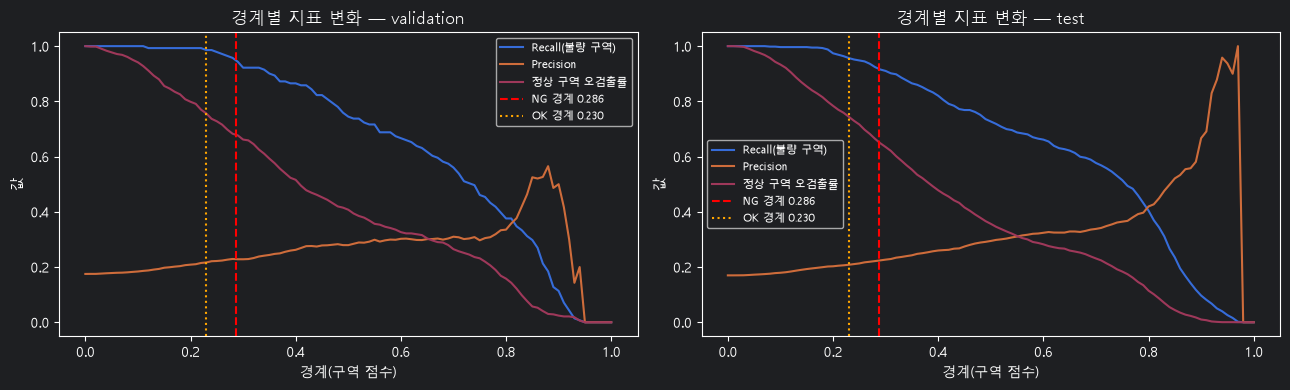

{'ok_upper': 0.22987894713878632, 'ng': 0.2864952087402344, 'source': 'validation only', 'model_version': 'lens_cnn_final-v1-756faef9'}


In [23]:
# 경계별 Precision/Recall 변화(검증·test)와 최종 경계 기록
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, split in zip(axes, ["validation", "test"]):
    y, s, _, _ = evaluate_on(final_run, split)
    grid = np.linspace(0, 1, 101)
    ax.plot(grid, [recall_score(y, s >= t, zero_division=0) for t in grid], label="Recall(불량 구역)")
    ax.plot(grid, [precision_score(y, s >= t, zero_division=0) for t in grid], label="Precision")
    ax.plot(grid, [((s >= t) & (y == 0)).sum() / max(1, (y == 0).sum()) for t in grid], label="정상 구역 오검출률")
    ax.axvline(final_run["ng"], color="red", ls="--", label=f"NG 경계 {final_run['ng']:.3f}")
    ax.axvline(final_run["ok_upper"], color="orange", ls=":", label=f"OK 경계 {final_run['ok_upper']:.3f}")
    ax.set(title=f"경계별 지표 변화 — {split}", xlabel="경계(구역 점수)", ylabel="값")
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "threshold_precision_recall.png", dpi=130)
plt.show()
THRESHOLDS = {"ok_upper": final_run["ok_upper"], "ng": final_run["ng"], "source": "validation only", "model_version": FINAL_MODEL_VERSION}
print(THRESHOLDS)

## PART 08. 사전 검사 효과 분석
**8-1. 실측(test 52장, 공식 정답):** test 사진은 전부 결함 사진입니다.
- 계산 가능: TP(NG로 분리), FN(놓침), **불량 유입 감소율 = TP/(TP+FN)**
- 계산 불가: FP·TN·정상 오검출률 → `null`(정상 사진 0장)
- REVIEW 사진의 두 시나리오를 따로 계산합니다.
  - (A) REVIEW를 후속 공정으로 보냄
  - (B) REVIEW를 재검·보류

**8-2. 팀 라벨 정상 사진:** `data/processed/lens_inference_team_labels.csv`가 있으면 실행됩니다. 두 명이 일치한 라벨만 씁니다. 이 경우 정상 사진의 실제 오검출률을 계산합니다.

**8-3. 시뮬레이션(가정):**
- 가상 생산 10,000개 × 가정 불량률 1·3·5%로 계산합니다.
- 불량 검출률은 8-1 **실측값**을 씁니다.
- 정상 오검출률은 8-2가 있으면 실측값을, 없으면 **구역 오검출률로 추정**한 값을 씁니다.
- 추정식: `1 − (1 − 구역 FPR)^(사진당 구역 수)` — 구역 사이가 독립이라고 가정한 값입니다.
- 데이터셋의 불량 비율을 실제 생산 불량률로 보지 않습니다.

> **주의 — 사진 하나에 구역이 많습니다.** 사진 점수를 구역 최댓값으로 정하므로, 구역 오검출률이 작아도 사진 단위 오검출은 커집니다(약 65구역 × 1% ≈ 정상 렌즈의 48% NG). test 불량 사진 Recall이 100%에 가까워도 정상 사진에서 얼마나 틀리는지 모르면 좋은 모델이라고 할 수 없습니다.
>
> 그래서 **참고 운영점**도 함께 계산합니다. 검증 정상 구역 점수로 "정상 사진 NG ≤ 5%"가 되는 구역 경계를 추정하고, 그 경계에서 test 불량 사진 Recall을 봅니다. 최종 사진 경계는 정상 사진(팀 라벨)으로 다시 정해야 합니다.

In [24]:
# 8-1 실측: test 사진 단위 사전 검사 효과
img = final_test["image"]
decisions = img["decisions"]
TP, FN_auto = int((decisions == "NG").sum()), int((decisions != "NG").sum())
review = int((decisions == "REVIEW").sum())
effect = {"total_images": img["images"], "actual_defect_images": img["defect_images"], "TP": TP, "FN": FN_auto, "FP": None, "TN": None,
          "defect_recall_auto_ng": TP / max(1, TP + FN_auto), "normal_false_positive_rate": None, "normal_reason": "test 정상 사진 0장",
          "scenario_A_review_sent_to_next_process": {"remaining_defects": FN_auto, "inflow_reduction": TP / max(1, img["images"])},
          "scenario_B_review_held_for_recheck": {"remaining_defects": int((decisions == "OK").sum()), "inflow_reduction": (TP + review) / max(1, img["images"]), "held_for_review": review},
          "note": "검증된 정답이 있는 이미지 단위의 효과이며 실제 완제품 불량률 감소를 의미하지 않음"}
print(json.dumps(effect, ensure_ascii=False, indent=1))

{
 "total_images": 52,
 "actual_defect_images": 52,
 "TP": 52,
 "FN": 0,
 "FP": null,
 "TN": null,
 "defect_recall_auto_ng": 1.0,
 "normal_false_positive_rate": null,
 "normal_reason": "test 정상 사진 0장",
 "scenario_A_review_sent_to_next_process": {
  "remaining_defects": 0,
  "inflow_reduction": 1.0
 },
 "scenario_B_review_held_for_recheck": {
  "remaining_defects": 0,
  "inflow_reduction": 1.0,
  "held_for_review": 0
 },
 "note": "검증된 정답이 있는 이미지 단위의 효과이며 실제 완제품 불량률 감소를 의미하지 않음"
}


In [25]:
# 8-2 팀 라벨 정상 사진(있을 때만): 두 명이 일치한 라벨로 정상 사진 오검출률을 실측합니다.
TEAM_LABEL_CSV = ROOT / "data/processed/lens_inference_team_labels.csv"
template = ROOT / "data/processed/lens_inference_team_labels_TEMPLATE.csv"
if not template.exists():
    lens_images[lens_images.split == "inference"][["image_key", "capture_group", "lens_group"]].assign(
        same_lens_as_labeled=lambda d: d.lens_group.isin(set(lens_images[lens_images.labeled].lens_group)),
        label_person1="", label_person2="", note="").to_csv(template, index=False, encoding="utf-8-sig")
team_eval = None
if TEAM_LABEL_CSV.exists():
    labels = pd.read_csv(TEAM_LABEL_CSV, dtype=str).fillna("")
    agreed = labels[(labels.label_person1 == labels.label_person2) & labels.label_person1.isin(["0", "1"])].copy()
    agreed = agreed[~agreed.same_lens_as_labeled.astype(str).str.lower().eq("true")]  # 학습 렌즈와 같은 조각은 제외
    agreed["y_true"] = agreed.label_person1.astype(int)
    rows_out = []
    for r in agreed.itertuples():
        row = lens_images.set_index("image_key").loc[r.image_key]
        if row.capture_group not in LENS_SCALE:
            continue
        image, _ = to_work(read_rgb(ROOT / row.path), row.capture_group)
        positions = grid_positions(image.shape, valid_region(image))
        padded = pad_to(preprocess(image, final_run["method"]))
        score = float(final_run["predict"](np.stack([padded[y:y + PATCH, x:x + PATCH] for y, x in positions])).max()) if positions else None
        rows_out.append({"image_key": r.image_key, "y_true": r.y_true, "score": score, "decision": decide(score, final_run["ok_upper"], final_run["ng"]) if score is not None else "REVIEW"})
    team_eval = pd.DataFrame(rows_out)
    team_eval.to_csv(PRED_DIR / "lens_predictions_team_labeled.csv", index=False, encoding="utf-8-sig")
    normals = team_eval[team_eval.y_true == 0]
    effect["team_labeled_normal_images"] = int(len(normals))
    effect["team_labeled_normal_false_positive_rate"] = float((normals.decision == "NG").mean()) if len(normals) else None
    print("팀 라벨 사용:", len(agreed), "장 (정상", len(normals), "장) / 정상 사진 NG 비율:", effect["team_labeled_normal_false_positive_rate"])
else:
    print("팀 라벨 CSV 없음 → 정상 사진 오검출률은 측정 불가로 둡니다. 라벨링 양식:", template.relative_to(ROOT))

팀 라벨 CSV 없음 → 정상 사진 오검출률은 측정 불가로 둡니다. 라벨링 양식: data\processed\lens_inference_team_labels_TEMPLATE.csv


주 경계(구역 Recall 95%)에서 정상 사진 NG 비율 추정: 1.0
참고 운영점(정상 사진 NG ≤5% 추정): {'target_normal_image_ng_rate': 0.05, 'allowed_patch_fpr': 0.0006330500871823963, 'ng_threshold': 0.9432409081840015, 'test_defect_image_recall': 0.17307692307692307, 'note': '검증 정상 구역 점수로 정한 추정 경계. 허용 구역 오검출률이 매우 작아 사실상 검증 정상 구역의 최고 점수 근처이며, 정상 사진이 없어 실제 정상 사진 NG 비율은 미검증'}


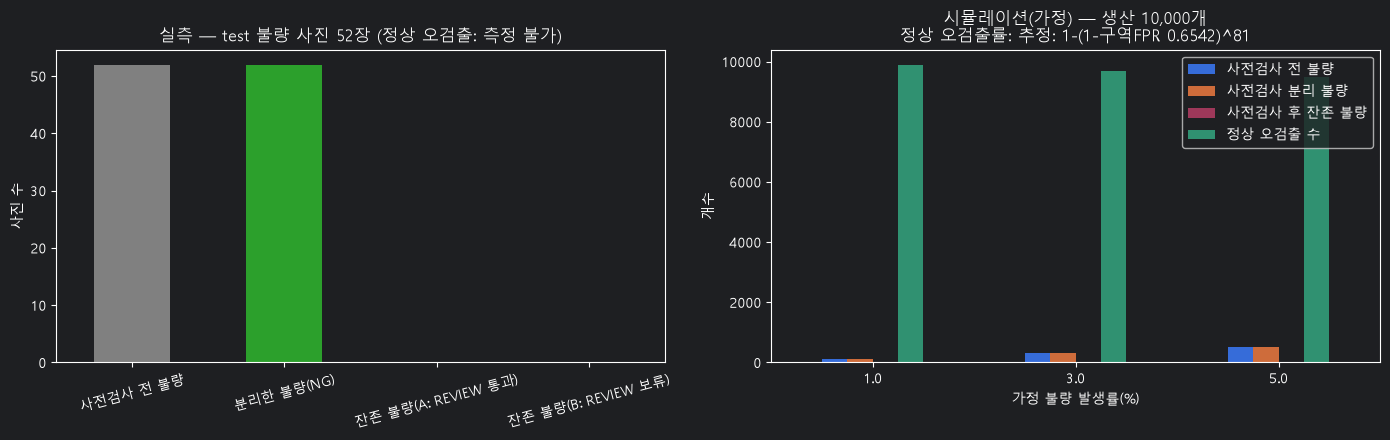

   가정 불량률(%)  생산 수량(가정)  사전검사 전 불량  사전검사 분리 불량  사전검사 후 잔존 불량  정상 오검출 수
0        1.0      10000      100.0       100.0           0.0    9900.0
1        3.0      10000      300.0       300.0           0.0    9700.0
2        5.0      10000      500.0       500.0           0.0    9500.0


In [26]:
# 8-3 시뮬레이션(가정)과 그래프
patches_per_image = final_test["rows"].groupby("image_key").size().median()
patch_fpr = final_test["metrics"]["false_positive_rate"]
if effect.get("team_labeled_normal_false_positive_rate") is not None:
    image_fpr, fpr_source = effect["team_labeled_normal_false_positive_rate"], "팀 라벨 정상 사진 실측"
else:
    image_fpr, fpr_source = 1 - (1 - patch_fpr) ** patches_per_image, f"추정: 1-(1-구역FPR {patch_fpr:.4f})^{patches_per_image:.0f}"
recall = effect["defect_recall_auto_ng"]

# 참고 운영점: '정상 렌즈 사진의 NG 비율 ≤ 5%'가 되도록 구역 경계를 추정합니다(검증 정상 구역만 사용).
yv_f, sv_f, _, _ = evaluate_on(final_run, "validation")
allowed_patch_fpr = 1 - (1 - 0.05) ** (1 / patches_per_image)
normal_scores = np.sort(sv_f[yv_f == 0])
IMAGE_LEVEL_NG = float(np.quantile(normal_scores, 1 - allowed_patch_fpr)) if len(normal_scores) else None
alt = image_scores(final_test["rows"], final_test["scores"])
effect["reference_image_operating_point"] = {"target_normal_image_ng_rate": 0.05, "allowed_patch_fpr": allowed_patch_fpr, "ng_threshold": IMAGE_LEVEL_NG,
                                             "test_defect_image_recall": float((alt >= IMAGE_LEVEL_NG).mean()) if IMAGE_LEVEL_NG is not None else None,
                                             "note": "검증 정상 구역 점수로 정한 추정 경계. 허용 구역 오검출률이 매우 작아 사실상 검증 정상 구역의 최고 점수 근처이며, 정상 사진이 없어 실제 정상 사진 NG 비율은 미검증"}
effect["estimated_image_fpr_at_main_threshold"] = 1 - (1 - patch_fpr) ** patches_per_image
print("주 경계(구역 Recall 95%)에서 정상 사진 NG 비율 추정:", round(effect["estimated_image_fpr_at_main_threshold"], 3))
print("참고 운영점(정상 사진 NG ≤5% 추정):", effect["reference_image_operating_point"])
sim = pd.DataFrame([{"가정 불량률(%)": 100 * rate, "생산 수량(가정)": SIM_PRODUCTION, "사전검사 전 불량": SIM_PRODUCTION * rate, "사전검사 분리 불량": SIM_PRODUCTION * rate * recall,
                     "사전검사 후 잔존 불량": SIM_PRODUCTION * rate * (1 - recall), "정상 오검출 수": SIM_PRODUCTION * (1 - rate) * image_fpr} for rate in SIM_DEFECT_RATES])
effect.update({"simulation_assumptions": {"production": SIM_PRODUCTION, "defect_rates": SIM_DEFECT_RATES, "recall_from": "test 실측", "image_fpr": image_fpr, "image_fpr_source": fpr_source}})
sim.to_csv(MET_DIR / "lens_preinspection_simulation.csv", index=False, encoding="utf-8-sig")
save_json(MET_DIR / "lens_preinspection_effect.json", effect)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
measured = pd.Series({"사전검사 전 불량": img["images"], "분리한 불량(NG)": TP, "잔존 불량(A: REVIEW 통과)": FN_auto, "잔존 불량(B: REVIEW 보류)": int((decisions == "OK").sum())})
measured.plot.bar(ax=axes[0], color=["gray", "tab:green", "tab:red", "tab:orange"])
axes[0].set(title=f"실측 — test 불량 사진 {img['images']}장 (정상 오검출: 측정 불가)", xlabel="", ylabel="사진 수")
axes[0].tick_params(axis="x", rotation=15)
sim.set_index("가정 불량률(%)")[["사전검사 전 불량", "사전검사 분리 불량", "사전검사 후 잔존 불량", "정상 오검출 수"]].plot.bar(ax=axes[1])
axes[1].set(title=f"시뮬레이션(가정) — 생산 {SIM_PRODUCTION:,}개\n정상 오검출률: {fpr_source}", xlabel="가정 불량 발생률(%)", ylabel="개수")
axes[1].tick_params(axis="x", rotation=0)
fig.tight_layout()
fig.savefig(FIG_DIR / "preinspection_effect.png", dpi=130)
plt.show()
print(sim.round(1))

## PART 09. Lens 검사 Gradio UI와 팀 통합용 `predict_lens(image)`
`predict_lens`는 **저장된 `.keras` 파일과 설정만으로** 추론합니다. 순서는 다음과 같습니다.
1. RGB 사진
2. 크기 묶음 확인 → 작업 배율로 축소
3. 전처리
4. 렌즈 영역 격자 구역(256)
5. Final CNN 점수
6. 최댓값
7. OK/NG/REVIEW

U-Net이 있으면 위치 마스크도 저장합니다. 정답 파일은 전혀 읽지 않습니다.
- **quick 모드 모델:** 기능 점검용이라 항상 REVIEW로 표시합니다.
- **예외:** 모델이 없거나 사진 크기가 적용 범위 밖이면 임의 점수 없이 REVIEW입니다.
- **결함 종류:** 예측하지 않습니다(지원 범위 밖).

In [27]:
# 팀 통합용 추론 함수 — 저장 모델을 다시 불러와 사용합니다.
LENS_CNN_PATH, LENS_UNET_PATH = MODEL_DIR / "lens_cnn_final.keras", MODEL_DIR / "lens_unet.keras"
_loaded = {}
def _load_models():
    if "cnn" not in _loaded:
        _loaded["cnn"] = keras.models.load_model(LENS_CNN_PATH, compile=False) if LENS_CNN_PATH.exists() and LENS_CNN_PATH.stat().st_size > 1000 else None
        _loaded["unet"] = keras.models.load_model(LENS_UNET_PATH, compile=False) if LENS_UNET_PATH.exists() and LENS_UNET_PATH.stat().st_size > 1000 else None
    return _loaded["cnn"], _loaded["unet"]

def predict_lens(image, save_mask=True):
    # image: (높이, 너비, 3) uint8 RGB. 반환: 팀 통합 규격 딕셔너리
    started = time.perf_counter()
    result = {"part_type": "Lens", "status": "REVIEW", "defect_score": None, "threshold": {"ok_upper": THRESHOLDS["ok_upper"], "ng": THRESHOLDS["ng"]},
              "model_version": FINAL_MODEL_VERSION, "mask_path": None, "inference_ms": None, "reason": "", "overlay": None}
    image = np.asarray(image)
    if image.ndim == 2:
        image = np.stack([image] * 3, axis=-1)
    image = image[..., :3].astype(np.uint8)
    cnn, unet = _load_models()
    group = capture_group(image.shape[1], image.shape[0])
    if cnn is None:
        result["reason"] = "Lens CNN 모델 파일이 없습니다 — 임의 결과를 내지 않습니다."
    elif group not in LENS_SCALE:
        result["reason"] = f"학습에 없던 사진 크기({image.shape[1]}×{image.shape[0]}) — 적용 범위 밖"
    else:
        work, _ = to_work(image, group)
        positions = grid_positions(work.shape, valid_region(work))
        if not positions:
            result["reason"] = "렌즈 영역을 찾지 못했습니다."
        else:
            padded = pad_to(preprocess(work, final_run["method"]))
            batch = np.stack([padded[y:y + PATCH, x:x + PATCH] for y, x in positions]).astype(np.float32)
            scores = np.concatenate([cnn(batch[i:i + 64], training=False).numpy().reshape(-1) for i in range(0, len(batch), 64)])
            score = float(scores.max())
            result["defect_score"] = score
            result["status"] = decide(score, THRESHOLDS["ok_upper"], THRESHOLDS["ng"])
            result["reason"] = "구역 점수 최댓값 기준 판정"
            if RUN_MODE == "quick":
                result["status"], result["reason"] = "REVIEW", "quick 모델(기능 점검용) — 판정을 확정하지 않습니다."
            if unet is not None:
                score_map = predict_full(lambda b: unet(b.astype(np.float32), training=False).numpy()[..., 0], work)
                pred = binarize(score_map, UNET_FINAL["threshold"] if UNET_FINAL else 0.5)
                result["overlay"] = overlay_image(work, None, pred)
                if save_mask:
                    folder = PRED_DIR / "ui_masks"
                    folder.mkdir(exist_ok=True)
                    path = folder / f"lens_mask_{datetime.now(KST).strftime('%Y%m%d_%H%M%S_%f')}.png"
                    save_png(path, (pred * 255).astype(np.uint8))
                    result["mask_path"] = str(path.relative_to(ROOT))
            else:
                y0, x0 = positions[int(scores.argmax())]  # U-Net이 없으면 가장 높은 구역을 사각형으로 표시(보조 시각화)
                overlay = work.copy()
                cv2.rectangle(overlay, (x0, y0), (x0 + PATCH, y0 + PATCH), (255, 0, 0), 3)
                result["overlay"] = overlay
    result["inference_ms"] = 1000 * (time.perf_counter() - started)
    return result

HISTORY_CSV = PRED_DIR / "lens_inspection_history.csv"
def append_history(result, source):
    row = {"time_kst": datetime.now(KST).isoformat(timespec="seconds"), "source": source, **{k: (json.dumps(v) if isinstance(v, dict) else v) for k, v in result.items() if k != "overlay"}}
    new = not HISTORY_CSV.exists()
    pd.DataFrame([row]).to_csv(HISTORY_CSV, mode="a", header=new, index=False, encoding="utf-8-sig" if new else "utf-8")

# 자체 시험: test 사진 1장 + 적용 범위 밖 사진
before = len(pd.read_csv(HISTORY_CSV)) if HISTORY_CSV.exists() else 0
sample = read_rgb(ROOT / lens_images.set_index("image_key").loc[test_keys[0], "path"])
check = predict_lens(sample)
append_history(check, "self_test")
odd = predict_lens(np.full((300, 400, 3), 200, np.uint8), save_mask=False)
append_history(odd, "self_test_out_of_scope")
assert odd["status"] == "REVIEW" and odd["defect_score"] is None
assert len(pd.read_csv(HISTORY_CSV)) == before + 2
print({k: v for k, v in check.items() if k != "overlay"})
print("범위 밖:", odd["reason"])

{'part_type': 'Lens', 'status': 'NG', 'defect_score': 0.9125646948814392, 'threshold': {'ok_upper': 0.22987894713878632, 'ng': 0.2864952087402344}, 'model_version': 'lens_cnn_final-v1-756faef9', 'mask_path': 'outputs\\predictions\\ui_masks\\lens_mask_20261119_182605_081786.png', 'inference_ms': 10141.661799978465, 'reason': '구역 점수 최댓값 기준 판정'}
범위 밖: 학습에 없던 사진 크기(400×300) — 적용 범위 밖


In [28]:
# Gradio 검사 화면 (로컬 127.0.0.1, 공유 링크 없음)
if ENABLE_GRADIO:
    try:
        import gradio as gr
    except ImportError:
        gr = None
        print("gradio가 설치되어 있지 않습니다: pip install gradio")
    if gr is not None:
        def ui_inspect(image):
            if image is None:
                return "사진을 올려 주세요.", None, None
            r = predict_lens(image)
            append_history(r, "gradio_upload")
            score = "없음" if r["defect_score"] is None else f"{r['defect_score']:.4f}"
            text = (f"## 판정: {r['status']}\n- 결함 점수(구역 최댓값, 보정된 확률 아님): {score}\n"
                    f"- 경계: OK < {r['threshold']['ok_upper']:.4f} ≤ REVIEW < {r['threshold']['ng']:.4f} ≤ NG\n- 사유: {r['reason']}\n"
                    f"- 모델: {r['model_version']} / U-Net 위치: {'사용' if r['mask_path'] else '없음(최고 점수 구역 표시)'}{' (실험용)' if UNET_EXPERIMENTAL and r['mask_path'] else ''}\n"
                    f"- 추론 시간: {r['inference_ms']:.0f} ms / 이력: {HISTORY_CSV.relative_to(ROOT)}")
            return text, image, r["overlay"]
        with gr.Blocks(title="FoldedVision AI — Lens 검사") as demo:
            gr.Markdown("### FoldedVision AI — Lens 외관 결함 검사 (공개 데이터 PoC, 결함 종류는 예측하지 않음)")
            upload = gr.Image(type="numpy", label="Lens 사진 업로드")
            button = gr.Button("검사")
            verdict = gr.Markdown()
            with gr.Row():
                original = gr.Image(label="원본")
                located = gr.Image(label="결함 위치 (빨강)")
            button.click(ui_inspect, upload, [verdict, original, located])
        demo.launch(share=False, server_name="127.0.0.1", inbrowser=True)

* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.


## 팀 통합 파일 생성
| 파일 | 내용 |
|---|---|
| `outputs/integration/lens_predictions.csv` | test 사진별 결과(Ring 팀원과 같은 컬럼). y_true는 공식 정답(전부 1=불량), inference는 제외 |
| `outputs/integration/lens_metrics.json` | 사진 단위 값(계산 불가는 null+이유), 구역 단위 전체 지표는 `patch_level`에 |
| `outputs/integration/lens_model_config.json` | 전처리·배율·구역·정규화·경계를 팀원이 추측하지 않도록 상세 기록 |

In [29]:
# 팀 통합 규격 파일 저장
image_score = image_scores(final_test["rows"], final_test["scores"])
predictions = pd.DataFrame({"image_id": [lens_images.set_index("image_key").loc[k, "image_id"] for k in image_score.index], "part_type": "Lens", "split": "test",
                            "y_true": 1, "defect_score": image_score.values, "threshold": THRESHOLDS["ng"],
                            "y_pred": (image_score.values >= THRESHOLDS["ng"]).astype(int), "decision": [decide(s, THRESHOLDS["ok_upper"], THRESHOLDS["ng"]) for s in image_score.values],
                            "model_version": FINAL_MODEL_VERSION})
predictions.to_csv(INTEG_DIR / "lens_predictions.csv", index=False, encoding="utf-8-sig")
pm = final_test["metrics"]
lens_metrics = {"dataset_name": DATASET_NAME, "task_type": "image_defect_detection_by_patch_cnn (사진 점수=256 구역 점수 최댓값; 구역 정답=실제 polygon 마스크)",
                "train_count": len(split_keys("train")), "validation_count": len(split_keys("validation")), "test_count": len(split_keys("test")),
                "threshold": THRESHOLDS["ng"], "ok_upper_threshold": THRESHOLDS["ok_upper"],
                "TP": effect["TP"], "FP": None, "TN": None, "FN": effect["FN"], "accuracy": None, "precision": None, "recall": effect["defect_recall_auto_ng"], "f1": None,
                "roc_auc": None, "average_precision": None, "false_positive_rate": effect.get("team_labeled_normal_false_positive_rate"),
                "defect_inflow_reduction": effect["defect_recall_auto_ng"],
                "null_reasons": {"FP/TN/accuracy/precision/f1/roc_auc/average_precision": "test에 공식 정상 사진 0장 — 사진 단위로 계산 불가",
                                 "false_positive_rate": "팀 라벨 정상 사진이 있을 때만 실측(PART 08-2)"},
                "estimated_normal_image_fpr_at_threshold": effect["estimated_image_fpr_at_main_threshold"],
                "reference_image_operating_point": effect["reference_image_operating_point"],
                "review_count": int((predictions.decision == "REVIEW").sum()), "defect_passed_as_ok": int((predictions.decision == "OK").sum()),
                "patch_level": {k: pm[k] for k in ["threshold", "accuracy", "precision", "recall", "f1", "roc_auc", "average_precision", "TP", "FP", "TN", "FN", "false_positive_rate"]},
                "patch_level_counts": {"test_patches": int(len(final_test["y"])), "test_defect_patches": int(final_test["y"].sum())},
                "segmentation_unet_test": unet_test if UNET_FINAL is not None else None, "model_version": FINAL_MODEL_VERSION, "mode": RUN_MODE,
                "evaluation_note": "공개 데이터의 공식 Val(같은 렌즈 11장 제외)을 최종 평가로 사용. 실제 생산라인 성능 아님."}
save_json(INTEG_DIR / "lens_metrics.json", lens_metrics)
lens_model_config = {
    "model_name": "lens_cnn_final", "model_version": FINAL_MODEL_VERSION, "model_path": "models/lens_cnn_final.keras", "model_sha256": FINAL_MODEL_SHA,
    "input_size": [IMAGE_SIZE, IMAGE_SIZE, 3], "color_mode": "RGB", "channel_order": "RGB (OpenCV로 읽으면 BGR→RGB 변환 필수)",
    "normalization": "모델 내부 Rescaling(1/255). 입력은 0~255 값을 float32로 그대로 넣음(따로 나누지 말 것)",
    "preprocessing": {"step1_capture_group": {"A_512_quadrant": "512×512", "B_2448x2048": "2448×2048", "C_3500_square": "짧은 변≥3000, 가로·세로 차 5% 이내", "other": "적용 범위 밖→REVIEW"},
                      "step2_scale": LENS_SCALE, "step2_interpolation": "cv2.INTER_AREA (배율 1.0이면 그대로)",
                      "step3_filter": final_run["method"], "step3_filter_detail": {"rgb": "없음", "clahe": "LAB L채널 CLAHE clipLimit=2.0 tile=(8,8)", "median": "cv2.medianBlur 3"}[final_run["method"]],
                      "step4_valid_region": "회색 변환→GaussianBlur 5×5→밝기>60→Opening 5×5→전체의 5% 이상 덩어리만",
                      "step5_patches": {"size": PATCH, "stride": STRIDE, "grid": "0, stride, 2·stride, …, 마지막은 끝에 맞춤; 256보다 작으면 오른쪽·아래 0 채움", "valid_min": VALID_MIN},
                      "step6_aggregation": "사진 점수 = 구역 점수 최댓값"},
    "label_mapping": {"0": "정상 구역(결함 픽셀 0)", "1": "불량 구역(결함 픽셀 ≥4)"}, "positive_class": 1,
    "threshold": {"ok_upper": THRESHOLDS["ok_upper"], "ng": THRESHOLDS["ng"], "rule": "score≥ng→NG, score<ok_upper→OK, 그 사이 REVIEW", "source": "validation (불량 구역 Recall 95%/99%)"},
    "output_type": "sigmoid 점수(0~1, 높을수록 불량). 보정된 확률 아님", "mask_model_path": "models/lens_unet.keras" if UNET_FINAL is not None else None,
    "mask_threshold": UNET_FINAL["threshold"] if UNET_FINAL is not None else None, "mask_model_experimental": UNET_EXPERIMENTAL,
    "dataset_source": "VISION Datasets (Hugging Face VISION-Workshop/VISION-Datasets) Lens.tar.gz, 주석 CC BY-NC 4.0",
    "limitations": ["공식 정상 사진 0장: 사진 단위 정상 오검출률 미측정(팀 라벨로 보완 가능)", "구역 정상 = 결함 사진 안의 주석 없는 영역(미표시 미세 결함 가능)",
                    "같은 렌즈 판정은 512 조각 가장자리 기반 추정", "결함 종류 예측 안 함", "공개 데이터 PoC — 실제 생산 성능 아님"]}
save_json(INTEG_DIR / "lens_model_config.json", lens_model_config)
print(predictions.head())
print("통합 파일:", [p.name for p in INTEG_DIR.iterdir()])

     image_id part_type split  y_true  defect_score  threshold  y_pred  \
0  val_000066      Lens  test       1      0.912565   0.286495       1   
1  val_000067      Lens  test       1      0.913214   0.286495       1   
2  val_000068      Lens  test       1      0.801109   0.286495       1   
3  val_000069      Lens  test       1      0.858727   0.286495       1   
4  val_000070      Lens  test       1      0.818223   0.286495       1   

  decision               model_version  
0       NG  lens_cnn_final-v1-756faef9  
1       NG  lens_cnn_final-v1-756faef9  
2       NG  lens_cnn_final-v1-756faef9  
3       NG  lens_cnn_final-v1-756faef9  
4       NG  lens_cnn_final-v1-756faef9  
통합 파일: ['lens_metrics.json', 'lens_model_config.json', 'lens_predictions.csv']


## 최종 보고서 자동 작성
이번 실행에서 **실제로 계산된 값만** 모아 `outputs/metrics/lens_final_report.md`에 씁니다. 포트폴리오 요약도 함께 들어갑니다.

In [30]:
# 최종 보고서(실측값만 사용)
def fmt(v, pct=False):
    if v is None:
        return "N/A"
    return f"{100 * v:.1f}%" if pct else (f"{v:.4f}" if isinstance(v, float) else str(v))
b, f = test_results["CNN Baseline"]["metrics"], final_test["metrics"]
lines = [f"# Lens 최종 보고 ({RUN_MODE})", "", "> " + ("**quick 모드: 기능 점검용 — 성능으로 쓰지 말 것**" if QUICK else "full 모드 실측 결과") + " / 공개 데이터 PoC", "",
         "## 1~3. 데이터", f"- 총 사진 {lens_audit['total_images']}장 (train {lens_audit['images_per_split']['train']} / val {lens_audit['images_per_split']['val']} / inference {lens_audit['images_per_split']['inference']})",
         f"- 공식 정상 0장 / 불량 {lens_audit['defect_images_official']}장 / 정답 없음 {lens_audit['inference_images_without_label']}장",
         f"- 결함 종류: {', '.join(LENS_CATEGORIES)} — 개수 {lens_audit['instances_per_category']}",
         f"- 분할: train {len(split_keys('train'))} / validation {len(split_keys('validation'))} / test {len(split_keys('test'))}장 (공식 Val 중 같은 렌즈 11장 제외)", "",
         "## 4~6. CNN (test 구역)", "| 지표 | Baseline | Final |", "|---|---|---|"]
lines += [f"| {k} | {fmt(b[k])} | {fmt(f[k])} |" for k in ["accuracy", "precision", "recall", "f1", "roc_auc", "average_precision", "FN", "FP", "false_positive_rate"]]
lines += ["", f"- 최종 선택: {best_id} (validation AP {final_run['val_ap']:.4f}, Baseline {baseline_run['val_ap']:.4f})",
          "- " + ("validation AP 기준으로 Baseline보다 나았음" if final_run["val_ap"] > baseline_run["val_ap"] else "**Improved가 validation에서 Baseline보다 낫지 않았음**"), "",
          "## 7. U-Net (test)", (f"- 평균 Dice {unet_test['defect_image_mean_dice']:.3f} / 픽셀 Dice {unet_test['pixel_dice']:.3f} / IoU {unet_test['pixel_iou']:.3f} / Pixel P {unet_test['pixel_precision']:.3f} R {unet_test['pixel_recall']:.3f} / 실험용 {UNET_EXPERIMENTAL}" if UNET_FINAL is not None else "- 학습 안 함"),
          f"- 규칙 기준선 평균 Dice {rule_test['defect_image_mean_dice']:.3f}", "",
          "## 8~11. 판정·사전 검사 효과 (test 사진)", f"- 경계 OK<{THRESHOLDS['ok_upper']:.4f} / NG≥{THRESHOLDS['ng']:.4f} (validation)",
          f"- 자동 NG 불량 Recall {fmt(effect['defect_recall_auto_ng'], True)} (목표 95%: {('수치상 95% 이상이나 정상 사진 오검출을 검증하지 못해 달성으로 보지 않음' if effect['estimated_image_fpr_at_main_threshold'] > 0.2 or effect.get('team_labeled_normal_false_positive_rate') is None else '달성') if effect['defect_recall_auto_ng'] >= 0.95 else '미달'}) / REVIEW {review}장 / OK로 통과된 불량 {int((decisions == 'OK').sum())}장",
          f"- 불량 유입 감소율 A(REVIEW 통과) {fmt(effect['scenario_A_review_sent_to_next_process']['inflow_reduction'], True)} / B(REVIEW 보류) {fmt(effect['scenario_B_review_held_for_recheck']['inflow_reduction'], True)}",
          f"- 정상 오검출률(사진): {fmt(effect.get('team_labeled_normal_false_positive_rate'), True)} / 구역 FPR {fmt(f['false_positive_rate'], True)}",
          f"- 주 경계에서 정상 사진 NG 비율 추정: {fmt(effect['estimated_image_fpr_at_main_threshold'], True)}" + (" → **정상 렌즈 대부분이 NG로 갈 위험. 사진 경계는 정상 사진 확보 후 다시 정해야 함**" if effect["estimated_image_fpr_at_main_threshold"] > 0.2 else ""),
          f"- 참고 운영점(정상 사진 NG ≤5% 추정 경계 {fmt(effect['reference_image_operating_point']['ng_threshold'])}): test 불량 사진 Recall {fmt(effect['reference_image_operating_point']['test_defect_image_recall'], True)}", "",
          "## 12. 팀 통합 파일", "- models/lens_cnn_baseline.keras, lens_cnn_final.keras" + (", lens_unet.keras" if UNET_FINAL is not None else ""),
          "- outputs/integration/lens_predictions.csv, lens_metrics.json, lens_model_config.json", "",
          "## 포트폴리오 요약",
          "- 문제 정의: 렌즈 외관 결함 미검출 시 후속 공정 유입 → 사진 기반 사전 검사 가능성 검증",
          "- 데이터: 공개 VISION Lens(결함 polygon 5종). 정상 사진이 없어 결함 사진 내 정상 구역으로 이진 정답 구성, 같은 렌즈 누수 제거",
          "- 전처리: 크기 묶음별 배율(작은 결함 보존 확인) + 256 구역, RGB/CLAHE/Median 비교",
          f"- CNN: Baseline AP {fmt(b['average_precision'])} → Final AP {fmt(f['average_precision'])} (test 구역)",
          "- 결함 위치: U-Net(BCE vs BCE+Dice) + 규칙 기준선 비교",
          f"- 사전 검사 효과: test 불량 사진 자동 NG {fmt(effect['defect_recall_auto_ng'], True)}",
          "- 결론·한계: 정상 사진이 없어 사진 단위 오검출률은 미측정 — 팀 라벨 또는 정상 데이터 확보가 다음 단계"]
(MET_DIR / "lens_final_report.md").write_text("\n".join(lines), encoding="utf-8")
print("\n".join(lines))

# Lens 최종 보고 (full)

> full 모드 실측 결과 / 공개 데이터 PoC

## 1~3. 데이터
- 총 사진 222장 (train 66 / val 63 / inference 93)
- 공식 정상 0장 / 불량 129장 / 정답 없음 93장
- 결함 종류: Fiber, Flash Particle, Hole, Surface Damage, Tear — 개수 {'Fiber': 515, 'Surface Damage': 105, 'Tear': 35, 'Hole': 28, 'Flash Particle': 16}
- 분할: train 50 / validation 16 / test 52장 (공식 Val 중 같은 렌즈 11장 제외)

## 4~6. CNN (test 구역)
| 지표 | Baseline | Final |
|---|---|---|
| accuracy | 0.4217 | 0.4434 |
| precision | 0.2213 | 0.2235 |
| recall | 0.9551 | 0.9206 |
| f1 | 0.3593 | 0.3596 |
| roc_auc | 0.6844 | 0.7560 |
| average_precision | 0.2724 | 0.4187 |
| FN | 26 | 46 |
| FP | 1946 | 1852 |
| false_positive_rate | 0.6874 | 0.6542 |

- 최종 선택: rgb_cw (validation AP 0.3492, Baseline 0.3147)
- validation AP 기준으로 Baseline보다 나았음

## 7. U-Net (test)
- 평균 Dice 0.284 / 픽셀 Dice 0.244 / IoU 0.139 / Pixel P 0.275 R 0.219 / 실험용 True
- 규칙 기준선 평균 Dice 0.159

## 8~11. 판정·사전 검사 효과 (test 사진)
- 경계 OK<0.2299 / NG≥0.2865 (validation)
- 자동 NG 불량 Recall 100.0% (